<a href="https://colab.research.google.com/github/laurabveiga/Donor-Segmentation/blob/main/Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Index

1.  [Donor Segmentation](#scrollTo=bqbwWrw1Iuqb)
    *   [Project Goal and Description](#scrollTo=AljJr0-9I2jl)
    *   [Variable Description](#scrollTo=rwknsFYWs3nA)
2.  [Preparing the Data](#scrollTo=9BENjU-LbKKU)
    *   [Connecting to Google Drive](#scrollTo=bUVq5WpcbKKV)
    *   [Importing Libraries](#scrollTo=avSHkrAgp5td)
    *   [Importing the Data](#scrollTo=T7PEi6ALbKKX)
3. [Holdout Method](#scrollTo=16DA6b0KYMyW)
    *   [Splitting the Data into Training and Validation](#scrollTo=B5Pwsse8BzZ5)
4.  [Data Understanding](#scrollTo=YfzFhfyxYMyS)
    *   [Data Types and Missing Values](#scrollTo=YLMtBGXjrNQ1)
    *   [Descriptive Statistics of Numerical Variables](#scrollTo=sWj73MFZYMyT)
    *   [Descriptive Statistics of Categorical Variables](#scrollTo=-UwyASCHAR3t)
    *   [Missing Value Analysis](#scrollTo=GiSRiUSlAqwf)
    *   [Identifier Uniqueness](#scrollTo=ihc6FfXhNZoK)
    *   [Analysis of Selected Numerical Variables Means](#scrollTo=2zT1fn9uN1Qp)
    *   [Analysis of Median Income](#scrollTo=aECa7mcJOJXh)
    *   [Analysis of Standard Deviation of Numerical Variables](#scrollTo=3bTavV4LOhCr)
    *   [Exploratory Visual Screening (PairGrid)](#scrollTo=GM92h-EbYMyU)
    *   [Histograms of Numerical Variables](#scrollTo=WciJGT5_I7a5)
    *   [Boxplots of Numerical Variables](#scrollTo=7sjZIlRLNhvK)
    *   [Spearman Correlation](#scrollTo=N1MJNkfPYMyU)
    *   [Scatterplot Analysis](#scrollTo=8AYXBCEkv835)
5.  [Data Preprocessing (Training Set)](#scrollTo=DV6cS-uBYMyX)
    *   [Incoherence Treatment](#scrollTo=HC8Vv8VUtEj4)
    *   [Outliers](#scrollTo=RGm7ol66YMyZ)
    *   [Missing Values](#scrollTo=_rdk0BEkYMyd)
    *   [Feature Engineering](#scrollTo=p-A-I3NdYlXL)
    *   [Feature Selection (Numerical Variables)](#scrollTo=HkQddsM4b4Ph)
    *   [Feature Selection (Categorical Variables)](#scrollTo=hChTY0P5wicS)
    *   [Encoding](#scrollTo=AHXahNByVip4)
    *   [Scaling the Data](#scrollTo=6q1bXnYCZkzo)
    *   [Final Feature Selection](#scrollTo=agDbCVvLwY53)
6.  [Data Preprocessing (Validation Set)](#scrollTo=5QKJ_TDuvVJc)
    *   [Incoherence Treatment](#scrollTo=AqYqAzlC2BHx)
    *   [Missing Values](#scrollTo=TsZaW08SxTpH)
    *   [Feature Engineering](#scrollTo=Np-Sld3kwlQo)
    *   [Encoding](#scrollTo=30uXyTq04a-G)
    *   [Scaling the Data](#scrollTo=mkNwbSPFGEDW)
    *   [Feature Selection](#scrollTo=zOzw130dy3jJ)
7.  [Separating Dataset from Target](#scrollTo=uYvAbrx4ZAx1)
8.  [Predictive Modeling](#scrollTo=5pMsaTJGcKvF)
    *   [Logistic Regression Model](#scrollTo=0T5kQvxwaC1O)
    *   [Decision Trees Model](#scrollTo=pKfuqGmKVM4k)
        *   [Parameter Tunning](#scrollTo=hlmOKcuVcKmO)
            *   [Entropy](#scrollTo=_Ra2yXJTcj5J)
            *   [Depth](#scrollTo=wXTnhRFp00Y6)
            *   [Leaf](#scrollTo=6u6JrQDN1UbM)
    *   [Neural Networks](#scrollTo=NaEfiZZm4JBg)
9.  [Deployment](#scrollTo=MZLUiKs-kbxa)
    *   [Importing the Test Data](#scrollTo=Sbd0xcKOkfA5)
    *   [Preprocessing](#scrollTo=q4Vwbwg9lfwN)
        *   [Incoherence Treatment](#scrollTo=mlsLsCxJnrPd)
        *   [Missing Values](#scrollTo=4tcVbgjf2BHf)
        *   [Feature Engineering](#scrollTo=58PDWSLio9ay)
        *   [Encoding](#scrollTo=03NE7kaMpMTD)
        *   [Scaling the Test Data](#scrollTo=H1yuK136piub)
        *   [Feature Selection](#scrollTo=LpKKAgVT2qp5)

# Donor Segmentation

The goal of this project is to segment donors into meaningful groups using clustering techniques.
By analyzing demographic, socioeconomic, and behavioral data, we aim to uncover distinct donor profiles.

These insights will help the organization better understand its audience and support more targeted
and effective fundraising strategies.

This table provides a detailed description of all variables included in the dataset:

| Attribute                   | Description                                                                                                                                                                                                                                                                                                                                                                                                                                            |
| --------------------------- | ------------------------------------------------------------------------------------------------------------------------------------- |
| CONTROL_NUMBER              | Unique identifier of each possible donor                                                                                                                                                                                                                                                                                                                                                                                                               |
| DONOR_AGE                   | Age as of last year's mail solicitation                                                                                                                                                                                                                                                                                                                                                                                                                |
| URBANICITY                  | Nature of the donor's location U = Urban C = City T = Town R = Rural S = Suburban                                                                                                                                                                                                                                                                                                                                                                      |
| SES                         | Code assigning each individual to one of 5 demographic profiles based on socioeconomic characteristics                                                                                                                                                                                                                                                                                                                                                 |
| HOME_OWNER                  | H if individual is a Homeowner, U if it is Unknown                                                                                                                                                                                                                                                                                                                                                                                                     |
| DONOR_GENDER                | Gender of individual                                                                                                                                                                                                                                                                                                                                                                                                                                   |
| INCOME_GROUP                | Code assigning each individual to one of 7 income group levels                                                                                                                                                                                                                                                                                                                                                                                         |
| WEALTH_RATING               | Code assigning each individual to one of 10 wealth rating groups                                                                                                                                                                                                                                                                                                                                                                                       |
| MEDIAN_HOME_VALUE           | Individuals’ median home value in $100's                                                                                                                                                                                                                                                                                                                                                                                                               |
| MEDIAN_HOUSEHOLD_INCOME     | Individuals' median household <br> income in $100's                                                                                                                                                                                                                                                                                                                                                                                                        |
| PCT_OWNER_OCCUPIED          | Percent of owner-occupied housing near where person lives                                                                                                                                                                                                                                                                                                                                                                                              |
| PER_CAPITA_INCOME           | Per Capita Income of neighborhood in which person lives                                                                                                                                                                                                                                                                                                                                                                                                |
| PCT_ATTRIBUTE1              | Percent of residents in person's neighborhood that are male and active military                                                                                                                                                                                                                                                                                                                                                                        |
| PCT_ATTRIBUTE2              | Percent of residents in person's neighborhood that are male and veterans                                                                                                                                                                                                                                                                                                                                                                               |
| PCT_ATTRIBUTE3              | Percent of residents in person's neighborhood that are Vietnam veterans                                                                                                                                                                                                                                                                                                                                                                                |
| PCT_ATTRIBUTE4              | Percent of residents in person's neighborhood that are WW2 veterans                                                                                                                                                                                                                                                                                                                                                                                    |
| PEP_STAR                    | If person achieved STAR donor status, given to individuals who have given to 3 consecutive campaigns                                                                                                                                                                                                                                                                                                                                                   |
| RECENT_STAR_STATUS          | If achieved STAR within last 4 years                                                                                                                                                                                                                                                                                                                                                                                                                   |
| CHILDREN                    | Number of children the individual has                                                                                                                                                                                                                                                                                                                                                                                                                  |
| RECENT_AVG_GIFT_AMT         | Average donation from the individual to the charitable organization in the last four years                                                                                                                                                                                                                                                                                                                                                             |
| RECENT_CARD_RESPONSE_PROP   | Number of times the individual has responded to a card solicitation from the charitable organization in the last four years                                                                                                                                                                                                                                                                                                                            |
| RECENCY_STATUS_96NK         | Donor status: A (active - made their first donation more than 12 months ago and has made a donation in the last 12 months.); <br> E (inactive - made a donation 25+ months ago.); F (first time - made their first donation in the last 6 months and has made just one donation.); <br>L (lapsing - made their last donation between 13-24 months ago); N (new - made their first donation in the last 12 months and is not a First time donor); S (star donor) |
| FREQUENCY_STATUS_97NK       | Number of times donated in last period (The period of recency for all groups except L and E is the last 12 months. For L it is 13-24 months ago, and for E it is 25-36 months ago).                                                                                                                                                                                                                                                                    |
| RECENT_RESPONSE_PROP        | Proportion of responses to the individual to the number of (card or other) solicitations from the charitable organization in the last four years                                                                                                                                                                                                                                                                                                       |
| FILE_CARD_GIFT              | Lifetime average donation from the individual in response to all card solicitations from the charitable organization                                                                                                                                                                                                                                                                                                                                   |
| LIFETIME_CARD_PROM          | Total number of card promotions sent to the individual by the charitable organization                                                                                                                                                                                                                                                                                                                                                                  |
| LIFETIME_PROM               | Total number of promotions (card or other) sent to the individual by the charitable organization                                                                                                                                                                                                                                                                                                                                                       |
| RECENT_AVG_CARD_GIFT_AMT    | Average donation from the individual in response to a card solicitation from the charitable organization in the last four years                                                                                                                                                                                                                                                                                                                        |
| RECENT_RESPONSE_COUNT       | Number of times the individual has responded to a promotion (card or other) from the charitable organization in the last four years                                                                                                                                                                                                                                                                                                                    |
| RECENT_CARD_RESPONSE_COUNT  | Number of times the individual has responded to a card solicitation from the charitable organization in the last four years                                                                                                                                                                                                                                                                                                                            |
| MONTHS_SINCE_LAST_PROM_RESP | Number of months since the individual has responded to a promotion by the charitable organization                                                                                                                                                                                                                                                                                                                                                      |
| LIFETIME_GIFT_AMOUNT        | Total lifetime donation amount from the individual to the charitable organization                                                                                                                                                                                                                                                                                                                                                                      |
| LIFETIME_GIFT_COUNT         | Total number of donations from the individual to the charitable organization                                                                                                                                                                                                                                                                                                                                                                           |
| LIFETIME_MAX_GIFT_AMT       | Maximum donation amount from individual                                                                                                                                                                                                                                                                                                                                                                                                                |
| LIFETIME_MIN_GIFT_AMT       | Minimum donation amount from individual                                                                                                                                                                                                                                                                                                                                                                                                                |
| LAST_GIFT_AMT               | Amount donated in the individuals most recent donation                                                                                                                                                                                                                                                                                                                                                                                                 |
| CARD_PROM_12                | Number of card promotions sent to the individual by the charitable organization in the last 12 months                                                                                                                                                                                                                                                                                                                                                  |
| NUMBER_PROM_12              | Number of promotions (card or other) sent to the individual by the charitable organization in the last 12 months                                                                                                                                                                                                                                                                                                                                       |
| MONTHS_SINCE_LAST_GIFT      | Number of months since the most recent donation from the individual to the charitable organization                                                                                                                                                                                                                                                                                                                                                     |
| MONTHS_SINCE_FIRST_GIFT     | Number of months since the first donation from the individual to the charitable organization                                                                                                                                                                                                                                                                                                                                                           |


# 1.Preparing the data

### 1.1 Connecting to Google Drive

In [41]:
# Connect Google Colab to Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
path = '/content/drive/MyDrive/Colab Notebooks/ML - LGI/Predictive/'

Mounted at /content/drive


### 1.2 Importing Libraries

In [42]:
import pandas as pd
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from tqdm.notebook import tqdm, trange
tqdm.pandas(desc="Progress")
sns.set()
sns.set_theme(context='talk', palette='Dark2')
import warnings
warnings.simplefilter("ignore")
from IPython.display import Image
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import KNNImputer
from scipy.cluster import hierarchy

### 1.3 Importing the data

In [43]:
donors = pd.read_csv(path + 'donors_descriptive.csv' ,
                 sep = ',',
                 index_col = 'CONTROL_NUMBER'    #need to use semi-colon separators because of Portuguese Excel
                 # The first column (CONTROL_NUMBER) is used as index since it is a unique identifier
                    )
donors

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,...,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
61745,4.0,2.000000,33.0,M,0.0,1.0,H,5.0,20.0,9.0,...,0.00,17.50,0.0,0.000,2.0,0.154,0.0,2,T,NaN
112703,3.0,-2.341107,NaN,F,1.0,1.0,U,NaN,15.0,6.0,...,15.00,15.00,1.0,0.250,1.0,0.100,0.0,3,R,NaN
166437,4.0,0.000000,74.0,F,7.0,3.0,H,4.0,10.0,17.0,...,0.00,10.67,0.0,0.000,3.0,0.231,1.0,1,U,NaN
170621,4.0,4.000000,61.0,M,13.0,1.0,H,6.0,11.0,28.0,...,10.00,10.00,2.0,0.286,2.0,0.111,0.0,1,U,NaN
44428,6.0,3.000000,75.0,M,3.0,4.0,H,3.0,7.0,9.0,...,5.67,5.40,3.0,0.600,5.0,0.500,0.0,2,C,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34797,5.0,0.000000,84.0,M,6.0,1.0,H,6.0,10.0,32.0,...,10.00,10.00,1.0,0.100,2.0,NaN,6.0,2,C,3.0
7550,7.0,1.000000,86.0,F,16.0,3.0,H,2.0,10.0,33.0,...,10.00,7.50,2.0,0.222,4.0,0.211,1.0,2,U,3.0
115215,6.0,2.000000,NaN,M,2.0,3.0,U,1.0,10.0,12.0,...,8.50,9.00,2.0,0.250,NaN,0.235,0.0,2,T,NaN


In [44]:
donors_target = pd.read_csv(path + 'donors_train_target.csv',
                            sep = ',',
                            index_col = 'CONTROL_NUMBER')

In [45]:
donors = donors.merge(donors_target,
                      on = 'CONTROL_NUMBER',
                      how = 'left')
donors

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,...,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
61745,4.0,2.000000,33.0,M,0.0,1.0,H,5.0,20.0,9.0,...,17.50,0.0,0.000,2.0,0.154,0.0,2,T,NaN,1
112703,3.0,-2.341107,NaN,F,1.0,1.0,U,NaN,15.0,6.0,...,15.00,1.0,0.250,1.0,0.100,0.0,3,R,NaN,1
166437,4.0,0.000000,74.0,F,7.0,3.0,H,4.0,10.0,17.0,...,10.67,0.0,0.000,3.0,0.231,1.0,1,U,NaN,0
170621,4.0,4.000000,61.0,M,13.0,1.0,H,6.0,11.0,28.0,...,10.00,2.0,0.286,2.0,0.111,0.0,1,U,NaN,0
44428,6.0,3.000000,75.0,M,3.0,4.0,H,3.0,7.0,9.0,...,5.40,3.0,0.600,5.0,0.500,0.0,2,C,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34797,5.0,0.000000,84.0,M,6.0,1.0,H,6.0,10.0,32.0,...,10.00,1.0,0.100,2.0,NaN,6.0,2,C,3.0,0
7550,7.0,1.000000,86.0,F,16.0,3.0,H,2.0,10.0,33.0,...,7.50,2.0,0.222,4.0,0.211,1.0,2,U,3.0,0
115215,6.0,2.000000,NaN,M,2.0,3.0,U,1.0,10.0,12.0,...,9.00,2.0,0.250,NaN,0.235,0.0,2,T,NaN,0


In this step, we loaded the dataset containing information about potential donors.

The dataset included demographic variables, socioeconomic indicators, and past donation behavior, which were essential for segmentation.

We set "CONTROL_NUMBER" as the index since it represented a unique identifier and did not contain meaningful information for clustering.

Taking into consideration the features we see, separate continuous variables from categoricals.

In [46]:
# Numerical variables
metric_features = [ 'DONOR_AGE', 'MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'PCT_OWNER_OCCUPIED', 'PER_CAPITA_INCOME', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4', 'CHILDREN', 'RECENT_AVG_GIFT_AMT', 'RECENT_CARD_RESPONSE_PROP', 'FREQUENCY_STATUS_97NK', 'RECENT_RESPONSE_PROP', 'FILE_CARD_GIFT', 'LIFETIME_CARD_PROM', 'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT', 'RECENT_CARD_RESPONSE_COUNT', 'MONTHS_SINCE_LAST_PROM_RESP']

# Categorical variables
categorical_features = ['DONOR_GENDER', 'SES', 'HOME_OWNER', 'INCOME_GROUP', 'WEALTH_RATING', 'PEP_STAR', 'RECENT_STAR_STATUS', 'RECENCY_STATUS_96NK', 'URBANICITY']

# Identifier(not used)
not_feature = ['CONTROL_NUMBER']

In this step, we separated the variables into numerical and categorical features.

We classified variables based on their meaning and excluded CONTROL_NUMBER, as it is only a unique identifier

# 3.Holdout Method




In this phase, we will handle Data Cleaning and Data Transformation, in order to prepare our data for visualization and examination of outliers and missing values.

Let's create a copy of the dataframe and store it as backup, we will use it later to create clusters from the trained K-means model.

### 3.1 Spliting the data into training and validation

To prevent data leakage, we split the dataset into training (80%) and validation (20%) sets immediately after loading, prior to any exploratory data analysis or preprocessing. Explicit `.copy()` calls ensure transformations on the training set never mutate the validation set in memory.

In [79]:
# Split into Training (80%) and Validation (20%) before any EDA to prevent data leakage
train_df, val_df = train_test_split(
    donors,
    test_size=0.20,
    stratify=donors['TARGET_B'],
    random_state=42
)

# Explicit copies to avoid SettingWithCopyWarning and accidental mutation across splits
train_df = train_df.copy()
val_df = val_df.copy()

print(f"Training set shape: {train_df.shape}")
print(f"Validation set shape: {val_df.shape}")

Training set shape: (10848, 40)
Validation set shape: (2712, 40)


# 2.Data Understanding





Look for data types and missing values.

In [285]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10848 entries, 151846 to 44945
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CARD_PROM_12                 10646 non-null  float64
 1   CHILDREN                     10632 non-null  float64
 2   DONOR_AGE                    7983 non-null   float64
 3   DONOR_GENDER                 10648 non-null  object 
 4   FILE_CARD_GIFT               10628 non-null  float64
 5   FREQUENCY_STATUS_97NK        10637 non-null  float64
 6   HOME_OWNER                   10631 non-null  object 
 7   INCOME_GROUP                 8201 non-null   float64
 8   LAST_GIFT_AMT                10637 non-null  float64
 9   LIFETIME_CARD_PROM           10633 non-null  float64
 10  LIFETIME_GIFT_AMOUNT         10629 non-null  float64
 11  LIFETIME_GIFT_COUNT          10644 non-null  float64
 12  LIFETIME_MAX_GIFT_AMT        10618 non-null  float64
 13  LIFETIME_MIN_GIF

In this step, we inspected the structure of the dataset using .info().

We verified the data types of each variable and the number of non-null values.

We observed that:


*   Most variables were already in appropriate formats    
*   The dataset contained both numerical (float) and categorical (object) variables
*   Several variables included missing values, which would need to be addressed

Show all rows where all values are missing, to delete them in the future.

In [286]:
len(train_df[train_df.isnull().all(1)])

0

We found that there were no rows with all values missing.

Therefore, no rows will be removed due to this.

Look for duplicate rows to delete them in the future.

In [287]:
len(train_df[train_df.duplicated()]) #by default it checks all rows

0

We found that there were no duplicate rows.

Therefore, no rows will be removed due to this.

Look at the main descriptive statistics of the numerical variables.

In [288]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
CARD_PROM_12,10646.0,5.376698,1.317631,1.000000,5.000,6.000,6.000,17.000000
CHILDREN,10632.0,1.986907,1.472423,-2.341107,1.000,2.000,3.000,6.264709
DONOR_AGE,7983.0,58.824089,17.472645,0.000000,46.000,60.000,73.000,108.934261
FILE_CARD_GIFT,10628.0,5.233428,4.810971,-10.100341,2.000,4.000,8.000,32.000000
FREQUENCY_STATUS_97NK,10637.0,1.991805,1.151197,-1.365242,1.000,2.000,3.000,5.283869
INCOME_GROUP,8201.0,3.923083,1.942727,-1.728999,2.000,4.000,5.000,9.490799
LAST_GIFT_AMT,10637.0,16.606022,13.160389,-21.718664,10.000,15.000,20.000,450.000000
LIFETIME_CARD_PROM,10633.0,18.618504,8.867459,-7.188999,11.000,18.000,26.000,55.000000
LIFETIME_GIFT_AMOUNT,10629.0,104.472582,111.349712,-245.473199,41.000,79.000,133.000,3775.000000
LIFETIME_GIFT_COUNT,10644.0,9.930385,9.120761,-18.583020,4.000,8.000,14.000,95.000000


We analyzed the main descriptive statistics of the numerical variables.

We examined measures such as mean, standard deviation, minimum, and maximum values.

We observed that:


*   Some variables showed a wide range of values, especially donation-related features
*   Certain variables contained negative or extreme values, which may indicate outliers or data inconsistencies


These observations suggested that scaling, outlier handling, and incoherence treatment might be necessary in later stages.

Look at the main descriptive statistics of the categorical variables.

In [289]:
train_df.describe(include = ['O'])

,DONOR_GENDER,HOME_OWNER,RECENCY_STATUS_96NK,SES,URBANICITY
count,10648,10631,10644,10618,10615
unique,3,2,6,5,6
top,F,H,A,2,S
freq,5773,5776,6541,5119,2468


In this step, we analyzed the categorical variables by examining their distribution.

We observed that most variables had a limited number of categories and some imbalance in category frequencies.

Using the methods `isna().sum()`, verify how many missing values do we have for each of the variables and  then convert into percentages.

In [290]:
train_df.isna().sum()

,0
CARD_PROM_12,202
CHILDREN,216
DONOR_AGE,2865
DONOR_GENDER,200
FILE_CARD_GIFT,220
FREQUENCY_STATUS_97NK,211
HOME_OWNER,217
INCOME_GROUP,2647
LAST_GIFT_AMT,211
LIFETIME_CARD_PROM,215


In [291]:
# Percentage of missing values
train_df.isna().sum()/train_df.shape[0]*100

,0
CARD_PROM_12,1.862094
CHILDREN,1.991150
DONOR_AGE,26.410398
DONOR_GENDER,1.843658
FILE_CARD_GIFT,2.028024
FREQUENCY_STATUS_97NK,1.945059
HOME_OWNER,2.000369
INCOME_GROUP,24.400811
LAST_GIFT_AMT,1.945059
LIFETIME_CARD_PROM,1.981932


We observed that  WEALTH_RATING and INCOME_GROUP showed a significantly higher number of missing values.

Remove Variables with Excessive Missing Values

We removed INCOME_GROUP and WEALTH_RATING because they showed a much higher percentage of missing values compared to the remaining variables.   



We decided to remove them instead of imputing them, since the proportion of missing data was too high to ensure reliable imputation. In this context, imputing these variables could distort the underlying data structure and introduce artificial patterns, which would negatively impact the quality of the clustering results.

value_counts: how many values we have for each level of categorical data

In [292]:
train_df['DONOR_GENDER'].value_counts()

,count
DONOR_GENDER,
F,5773
M,4300
U,575


In [293]:
train_df['SES'].value_counts()

,count
SES,
2,5119
1,3224
3,1831
?,235
4,209


In [294]:
train_df['HOME_OWNER'].value_counts()

,count
HOME_OWNER,
H,5776
U,4855


In [295]:
train_df['PEP_STAR'].value_counts()

,count
PEP_STAR,
1.000000,5265
0.000000,5263
-0.529861,58
2.003609,44


In [296]:
train_df['RECENT_STAR_STATUS'].value_counts()

,count
RECENT_STAR_STATUS,
0.000000,7216
1.000000,2320
3.000000,194
4.000000,172
5.000000,110
11.000000,102
7.000000,73
-7.806416,58
12.000000,57


In [297]:
train_df['RECENCY_STATUS_96NK'].value_counts()

,count
RECENCY_STATUS_96NK,
A,6541
S,2300
F,839
N,686
E,233
L,45


In [298]:
train_df['URBANICITY'].value_counts()

,count
URBANICITY,
S,2468
R,2197
C,2188
T,2180
U,1346
?,236


We analyzed the distribution of the categorical variables to understand donor profiles.

We observed that female donors were more frequent, SES was concentrated in lower levels, and active donors were the largest group. HOME_OWNER was relatively balanced.

We also identified invalid or unexpected values, such as ? in categorical variables and inconsistent entries, for example 'U' in DONOR_AGE.

These issues would need to be addressed during preprocessing to ensure data quality.

Check Identifier Uniqueness

In [299]:
train_df.index.value_counts()

,count
CONTROL_NUMBER,
151846,1
1789,1
173523,1
123909,1
49812,1
...,...
24809,1
64671,1
7134,1


We checked whether CONTROL_NUMBER was unique for each observation.

The results showed that each identifier appeared only once, confirming that there were no duplicated donor IDs.


Analyze Selected Numerical Variables Means

In [300]:
train_df[['MEDIAN_HOME_VALUE', 'PCT_OWNER_OCCUPIED', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4', 'RECENT_AVG_GIFT_AMT']].mean()

,0
MEDIAN_HOME_VALUE,1070.978643
PCT_OWNER_OCCUPIED,69.425660
PCT_ATTRIBUTE1,1.085013
PCT_ATTRIBUTE2,30.617155
PCT_ATTRIBUTE3,29.688449
PCT_ATTRIBUTE4,32.649797
RECENT_AVG_GIFT_AMT,15.375076


We analyzed the average values of selected numerical variables and observed moderate recent donation amounts and a relatively high proportion of owner-occupied housing areas.

Analyze Median Income

In [301]:
train_df[['PER_CAPITA_INCOME']].median()

,0
PER_CAPITA_INCOME,13817.0


We used the median for PER_CAPITA_INCOME because income-related variables are often skewed by extreme values.

The median provided a more robust estimate of the typical income level in donors’ neighborhoods, indicating the central tendency without being influenced by unusually high or low values.

Analyze standard deviation of numerical variables

In [302]:
train_df.std(numeric_only=True)

,0
CARD_PROM_12,1.317631
CHILDREN,1.472423
DONOR_AGE,17.472645
FILE_CARD_GIFT,4.810971
FREQUENCY_STATUS_97NK,1.151197
INCOME_GROUP,1.942727
LAST_GIFT_AMT,13.160389
LIFETIME_CARD_PROM,8.867459
LIFETIME_GIFT_AMOUNT,111.349712
LIFETIME_GIFT_COUNT,9.120761


We analyzed the standard deviation to assess variability.

We observed high dispersion in variables such as PER_CAPITA_INCOME, MEDIAN_HOME_VALUE, and LIFETIME_GIFT_AMOUNT, and lower variability in variables like PEP_STAR and CARD_PROM_12.

These results reinforced the need for scaling before clustering, since high-variance variables could dominate distance-based algorithms.

Before finishing this section, we are going to make an exploratory visual screening of the different variables.
For that, we are going to use the PairGrid . Essencially, we will be looking at how variables are distributed and how they relate to one another.


Make use of the PairGrid.

In [303]:
#create sample of 0.5% (3000 rows) of the df - not perfect but otherwise the next cell would take HOURS to run  (I stopped after 6 hours)
sampled_df = train_df[metric_features].sample(frac=0.005, random_state = 100)

In [66]:
# First, ensure metric_features contains only unique names to avoid issues with duplicate columns
#metric_features = list(set(metric_features))

#sampled_df = donors[metric_features].sample(frac=0.005, random_state = 100)

#g = sns.PairGrid(sampled_df)
#g.map_upper(sns.histplot, color = 'salmon')
#g.map_lower(sns.kdeplot, fill=True, color = 'salmon')
#g.map_diag(sns.histplot, kde=True, color = 'salmon')

#plt.suptitle("Relationship Between Variables")

 #Create the 'images/Project' directory if it doesn't exist, including any intermediate directories
#os.makedirs('images/Project', exist_ok=True)

#plt.savefig("/content/drive/MyDrive/Colab Notebooks/ML - LGI/images/Pairplot_all_variables.png", dpi=300)

In [304]:
#deleting variable to save space
del sampled_df

In [305]:
# Load and display the previously saved PairGrid image
# This avoids recomputing the plot and allows quick visualization
Image('images/Pairplot_all_variables.png')

FileNotFoundError: No such file or directory: 'images/Pairplot_all_variables.png'

FileNotFoundError: No such file or directory: 'images/Pairplot_all_variables.png'

<IPython.core.display.Image object>

We used a PairGrid to explore variable distributions and relationships.

Due to its density, detailed interpretation is limited. Still, we observe some  skewed distributions and not a lot  strong linear relationships

 Overall, this serves as a general visual check; more focused plots are needed for deeper insights.

Histograms of Numerical Variables

  0%|          | 0/21 [00:00<?, ?it/s]

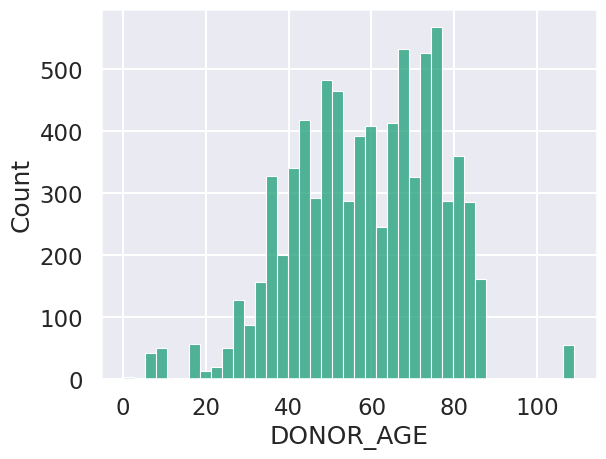

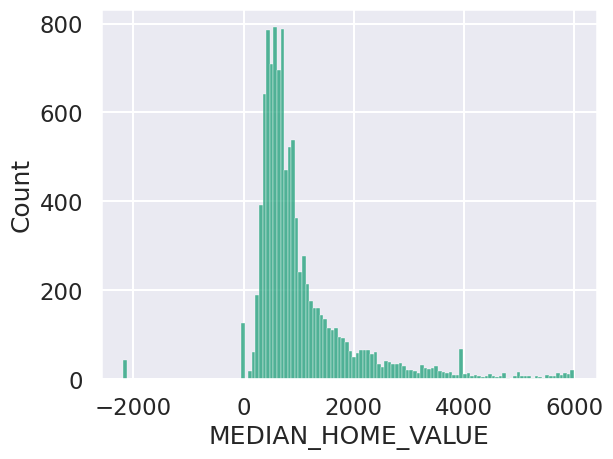

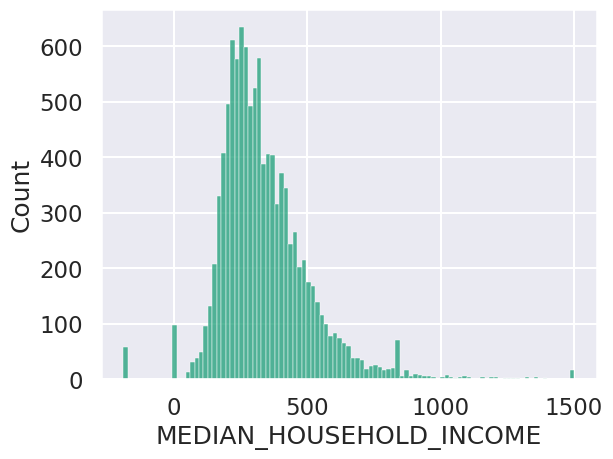

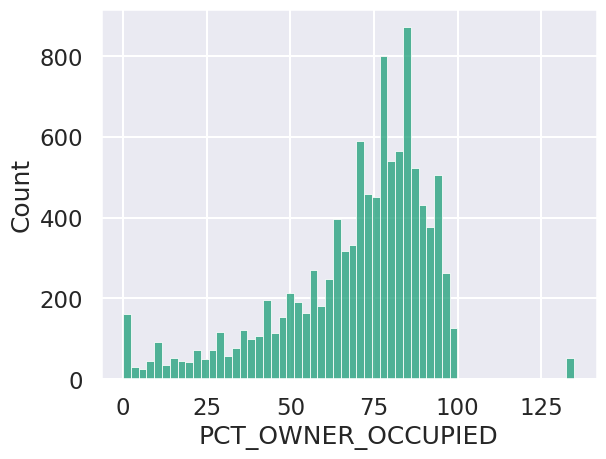

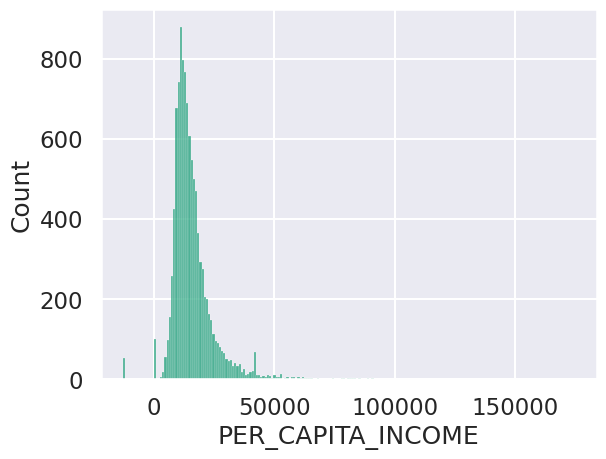

...

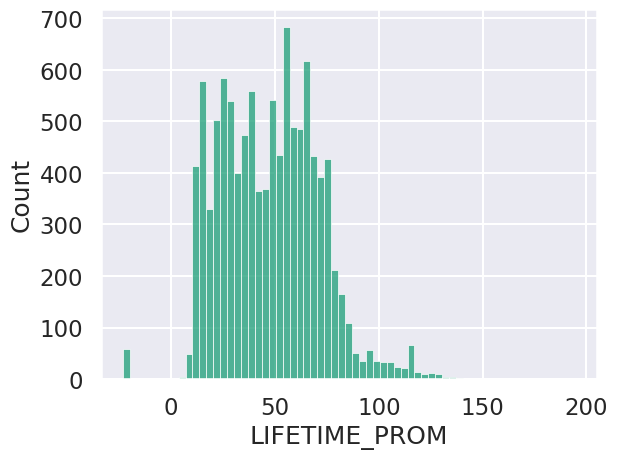

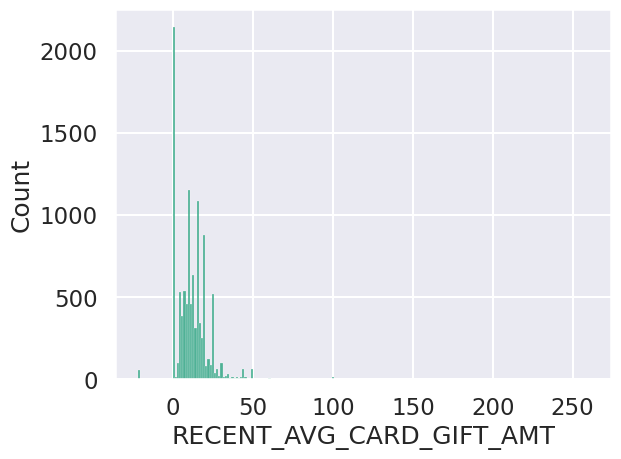

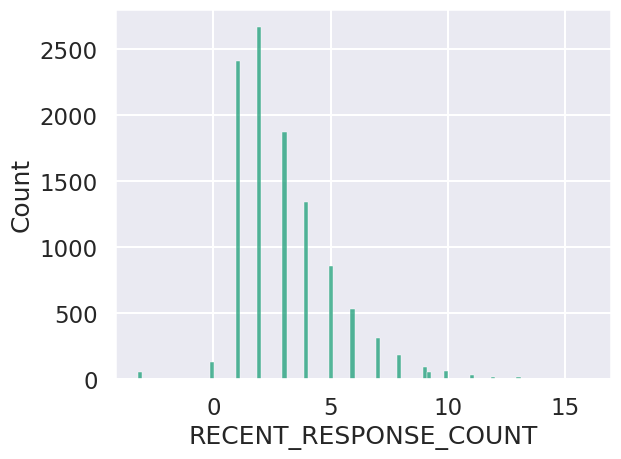

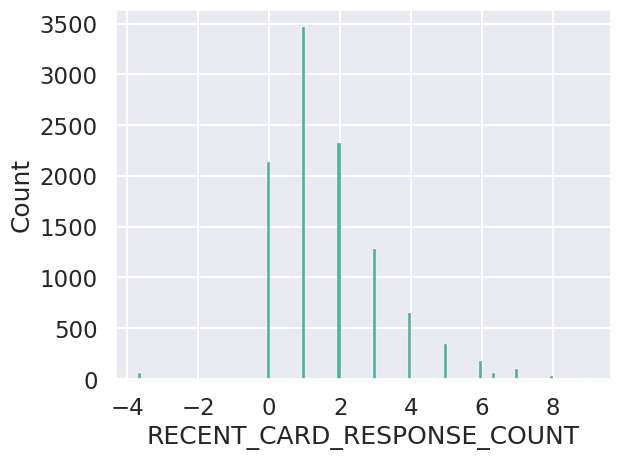

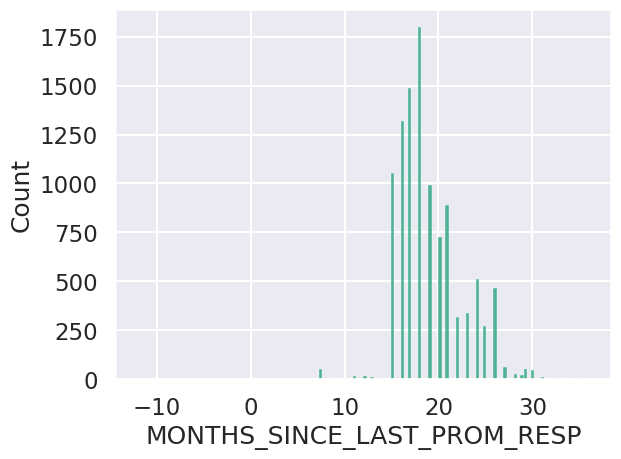

In [307]:
for i in tqdm(train_df[metric_features].columns):
  sns.histplot(data = train_df, x = i, palette = 'Dark2')
  plt.show()


 analyzed the histograms of the numerical variables to understand their distributions.

We observed that several variables, such as PER_CAPITA_INCOME, MEDIAN_HOUSEHOLD_INCOME, MEDIAN_HOME_VALUE, and RECENT_CARD_RESPONSE_PROP, were right-skewed and showed possible outliers.

We also identified unexpected negative values in some variables, including MEDIAN_HOME_VALUE and RECENT_CARD_RESPONSE_PROP, which did not make sense in this context.

These results reinforced the need for data cleaning, outlier treatment, and scaling before clustering.

Boxplots of Numerical Variables

  0%|          | 0/21 [00:00<?, ?it/s]

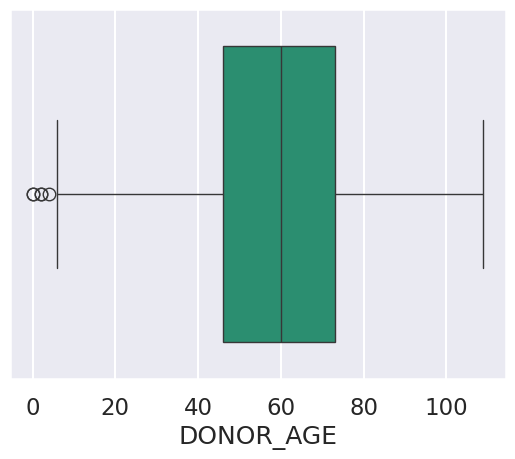

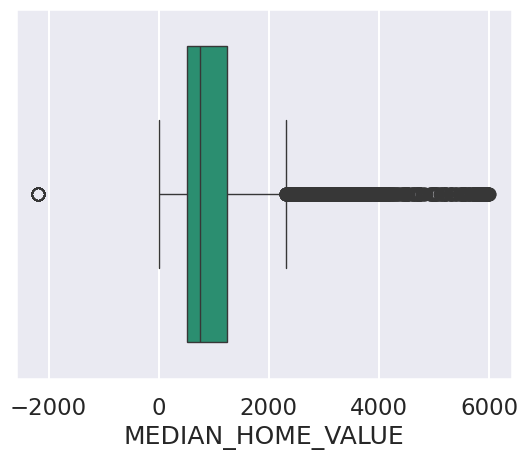

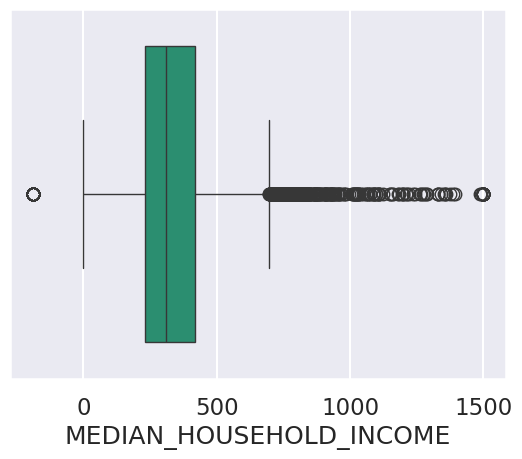

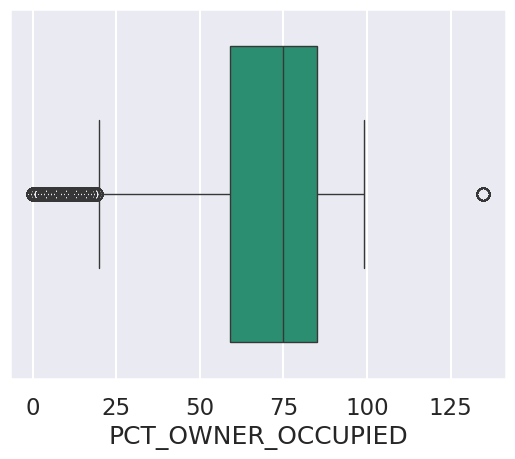

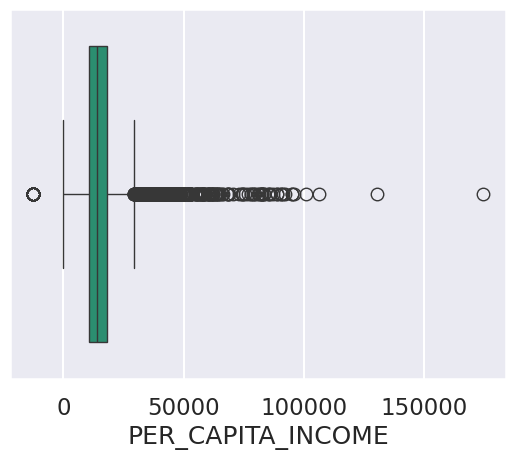

...

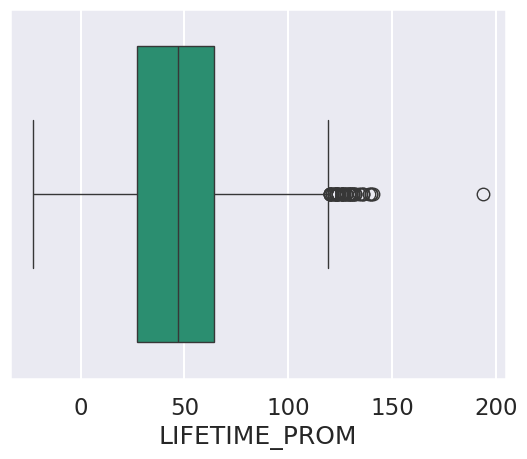

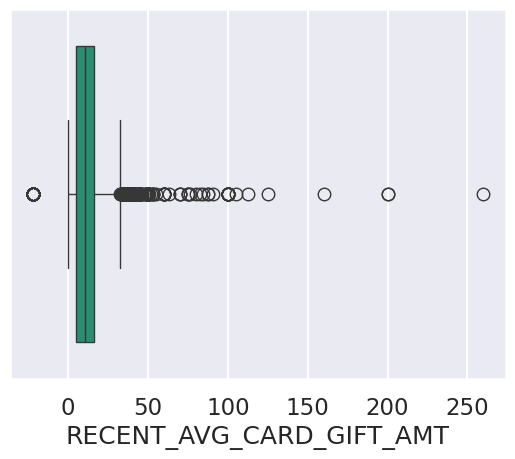

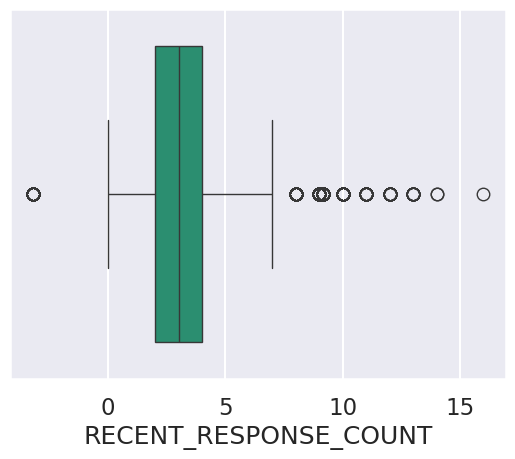

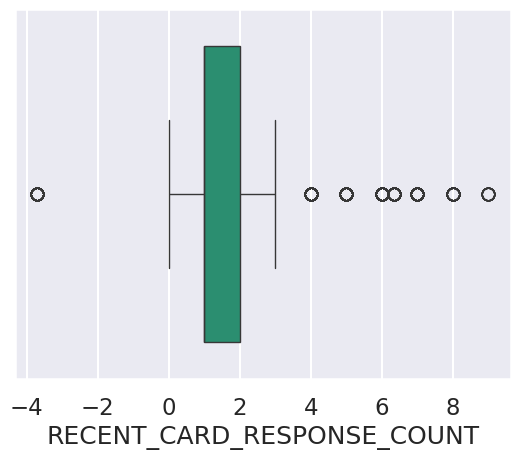

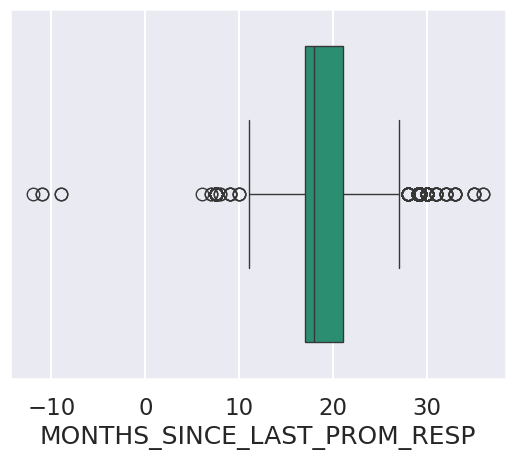

In [308]:
#plot a boxplot for each before the transformation
for i in tqdm(train_df[metric_features].columns):
    sns.boxplot(data = train_df, x = i, palette = 'Dark2')
    plt.show()

Most numerical variables show strong skewness and many outliers, especially:

PER_CAPITA_INCOME,
PCT_ATTRIBUTE1,
LIFETIME_PROM, FILE_CARD_GIFT,MEDIAN_HOUSEHOLD_INCOME, MEDIAN_HOME_VALUE

Some variables contain invalid negative values, such as:

PER_CAPITA_INCOME, RECENT_RESPONSE_PROP, FILE_CARD_GIFT, CHILDREN

Some variables like DONOR_AGE are more stable.

Plot the Spearman correlation indices for all metric features.

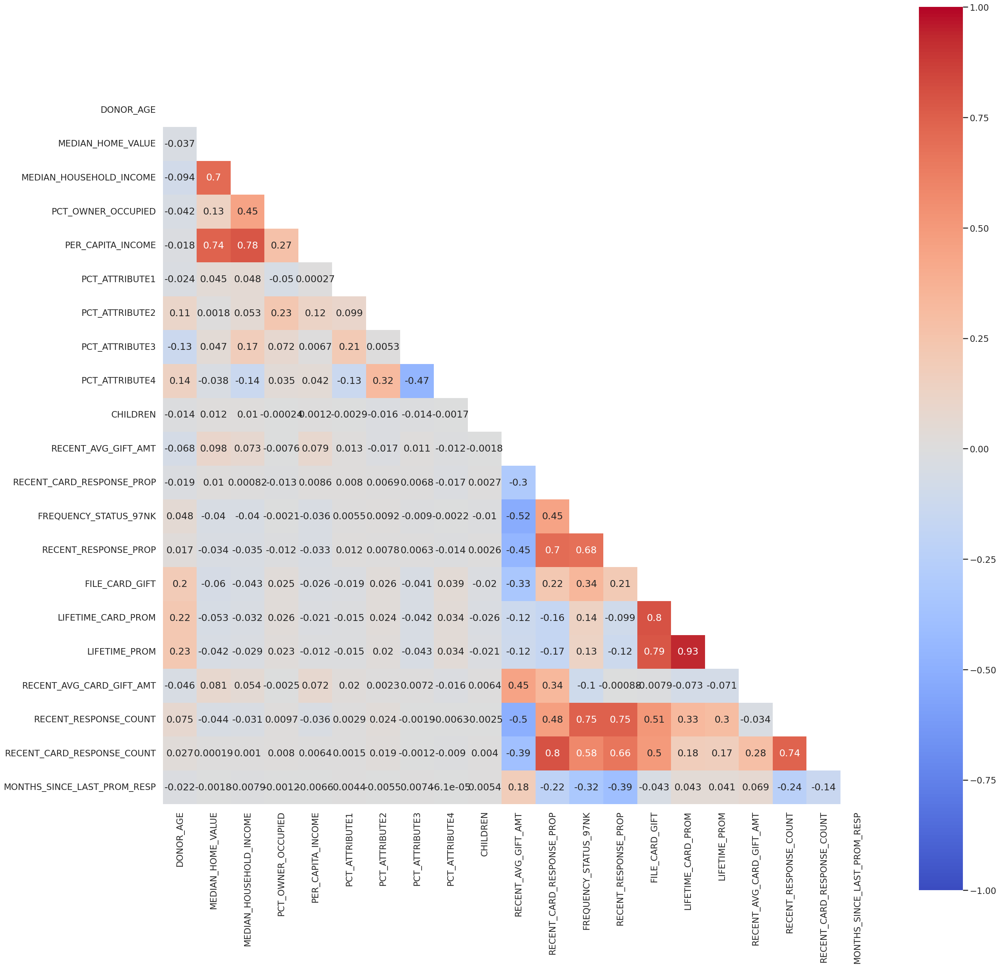

In [309]:
mask = np.zeros_like(train_df[metric_features].corr("spearman"))
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(30,30))
    ax = sns.heatmap(train_df[metric_features].corr("spearman"),mask=mask, annot = True,cmap='coolwarm',square=True,vmin=-1, vmax=1)

Variables too correlated:

*   LIFETIME_PROM & LIFETIME_CARD_PROM(very strong)
*   FILE_CARD_GIFT & LIFETIME_CARD_PROM
*   RECENCT_CARD_RESPONSE_PROP & RECENT_CARD_RESPONSE_COUNT
*   MEDIAN_HOUSEHOLD_INCOME & PER_CAPITA_INCOME
*   LIFETIME_PROM & FILE_CARD_GIFT

Negative relationships exist but are not strong enough to be considered high.


Weak correlations:

*  Most PCT_ATTRIBUTE variables



Scatterplot Analysis

<Axes: xlabel='LIFETIME_PROM', ylabel='LIFETIME_CARD_PROM'>

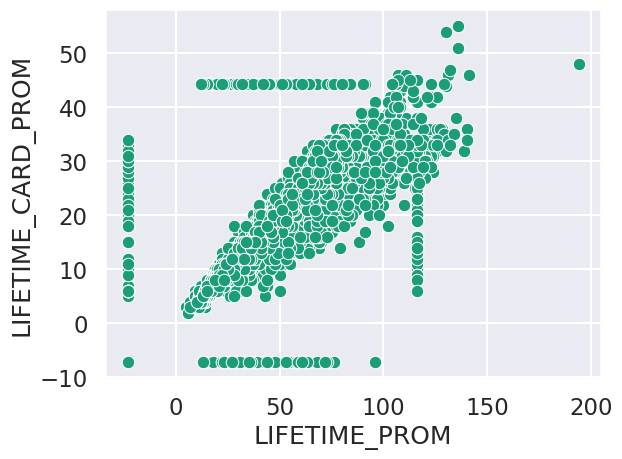

In [310]:
sns.scatterplot(data = train_df, x = 'LIFETIME_PROM', y='LIFETIME_CARD_PROM')

<Axes: xlabel='LIFETIME_PROM', ylabel='LIFETIME_CARD_PROM'>

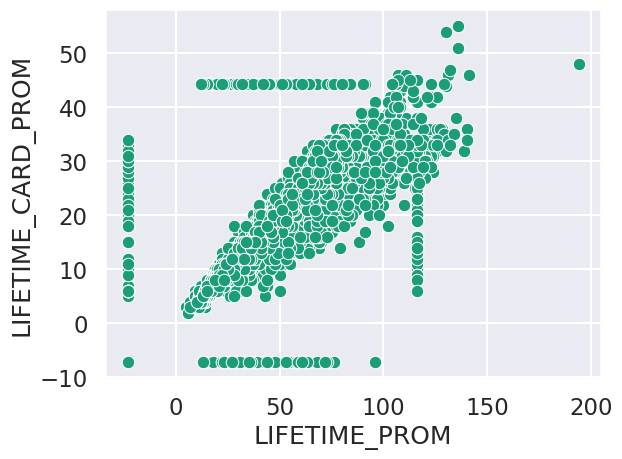

In [311]:
sns.scatterplot(data = train_df, x = 'LIFETIME_PROM', y='LIFETIME_CARD_PROM')

<Axes: xlabel='FILE_CARD_GIFT', ylabel='LIFETIME_CARD_PROM'>

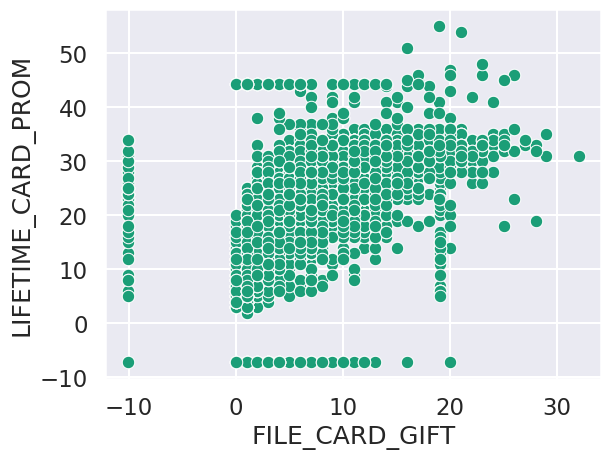

In [312]:
sns.scatterplot(x = 'FILE_CARD_GIFT', y = 'LIFETIME_CARD_PROM', data = train_df)

<Axes: xlabel='RECENT_CARD_RESPONSE_PROP', ylabel='RECENT_CARD_RESPONSE_COUNT'>

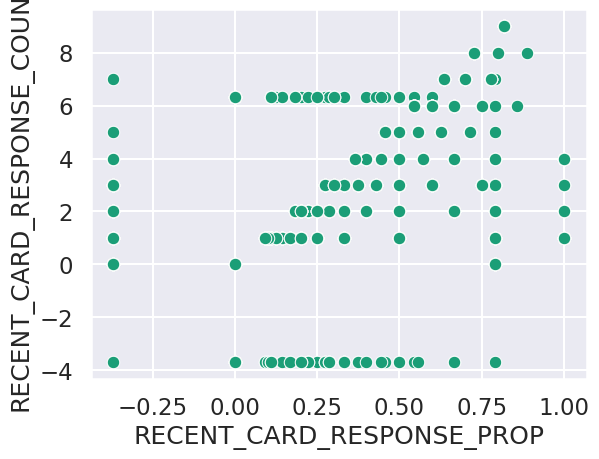

In [313]:
sns.scatterplot(data = train_df, x = 'RECENT_CARD_RESPONSE_PROP', y='RECENT_CARD_RESPONSE_COUNT')

<Axes: xlabel='MEDIAN_HOUSEHOLD_INCOME', ylabel='PER_CAPITA_INCOME'>

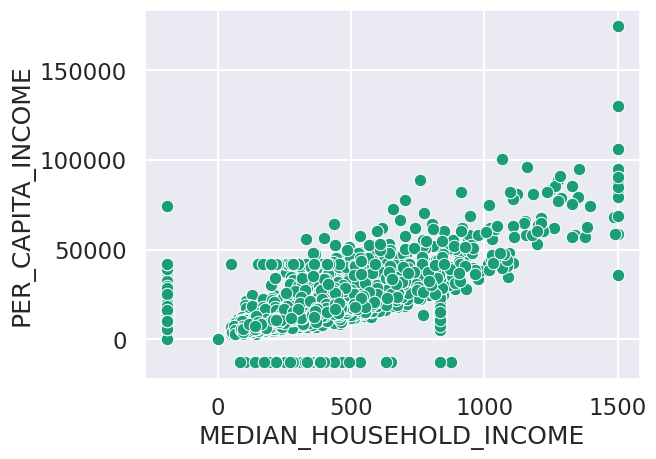

In [314]:
sns.scatterplot(data = train_df, x = 'MEDIAN_HOUSEHOLD_INCOME', y='PER_CAPITA_INCOME')

<Axes: xlabel='LIFETIME_PROM', ylabel='FILE_CARD_GIFT'>

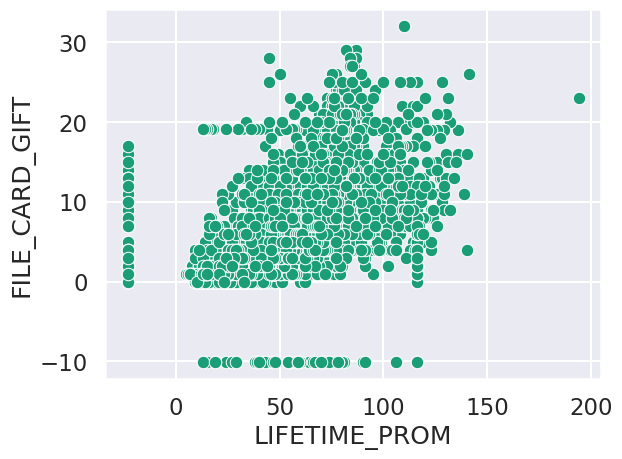

In [315]:
sns.scatterplot(data = train_df, x = 'LIFETIME_PROM', y='FILE_CARD_GIFT')

The plots confirm that these highly correlated variables move together, reinforcing the presence of multicollinearity and the need to remove  some of them.

# 4.Data Preprocessing (Training Set)

In [80]:
train_backup = train_df.copy()

### 4.1 Incoherence Treatment

When dealing with the major incoherences we found, we decided to remove the variables `LIFETIME_CARD_PROM`, `RECENT_CARD_RESPONSE_COUNT`and `PER_CAPITA_INCOME` as they highly correlate with other variables (check the previous heatmap)  and we are trying to reduce the dimensionality of our dataset.

**Incoherence categorical variables**

1. In `DONOR_GENDER` we noticed that some rows had a 'U' value (probably meaning 'unknown' so we decided to replace it for a missing value, treating it in the Missing Values phase.

2. For `SES` and `URBANICITY` we adopted the same approach, replacing '?' for missing values.

3. Regarding `RECENT_STAR_STATUS` we decided to transform all the values that are not 1 to 0, since it is a binary variable and 1 means that the donor as achieved STAR status (individuals who have donated to 3 consecutive campaigns) it the last 4 years.

In [81]:
train_backup['DONOR_GENDER'] = train_backup['DONOR_GENDER'].replace('U', np.nan)
train_backup['SES'] = train_backup['SES'].replace('?', np.nan)
train_backup['URBANICITY'] = train_backup['URBANICITY'].replace('?', np.nan)
train_backup.loc[
    (train_backup['RECENT_STAR_STATUS'] < 0) |
    (train_backup['RECENT_STAR_STATUS'] > 1),
    'RECENT_STAR_STATUS'
] = 1

In [82]:
train_backup['PEP_STAR'] = train_backup['PEP_STAR'].clip(0, 1)

**Incoherence numerical variables**

For the variables `PCT_OWNER_OCCUPIED`, `PCT_ATTRIBUTE1`, `PCT_ATTRIBUTE2`, `PCT_ATTRIBUTE3`, `PCT_ATTRIBUTE4` we decided to define a range from 0 to 100 since they all are percentages.

In [83]:
cols_pct = [
    'PCT_OWNER_OCCUPIED',
    'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2',
    'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4'
]

for col in cols_pct:
    train_backup[col] = train_backup[col].clip(0, 100)

For `RECENT_CARD_RESPONSE_PROP` and `RECENT_CARD_RESPONSE_PROP` we defined a range from 0 to 1, since these 2 variables are proportions.

In [84]:
cols_prop = [
    'RECENT_CARD_RESPONSE_PROP',
    'RECENT_RESPONSE_PROP'
]

for col in cols_prop:
    train_backup[col] = train_backup[col].clip(0, 1)

For `DONOR_AGE` we clipped all values smaller than 18 and greater than 100 as we considered that those should be the age limits for a donor.

In [85]:
train_backup['DONOR_AGE'] = train_backup['DONOR_AGE'].clip(18, 100)

For all the variables in the list below, we decided to clip all the negative values since it is impossible, for example, for a household to have negative income or for a donor to give a negative donation.

In [86]:
cols_non_negative = [
    'MEDIAN_HOME_VALUE', 'RECENT_AVG_GIFT_AMT',
    'LIFETIME_GIFT_AMOUNT', 'LIFETIME_MAX_GIFT_AMT',
    'LIFETIME_MIN_GIFT_AMT', 'LAST_GIFT_AMT', 'PER_CAPITA_INCOME', 'MEDIAN_HOUSEHOLD_INCOME'
]

for col in cols_non_negative:
    train_backup.loc[train_backup[col] < 0, col] = np.nan

In [87]:
cols_int = [
    'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT',
    'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT',
    'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12',
    'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'LIFETIME_CARD_PROM', 'RECENT_CARD_RESPONSE_COUNT'
]

for col in cols_int:
    train_backup[col] = train_backup[col].clip(lower=0).round().astype('Int64')

In [88]:
train_backup.describe()

,CARD_PROM_12,CHILDREN,DONOR_AGE,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,...,PER_CAPITA_INCOME,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,WEALTH_RATING,TARGET_B
count,10646.000000,10632.0,7983.000000,10628.0,10637.0,8201.000000,10582.000000,10633.0,10577.000000,10644.0,...,10584.000000,10652.0,10563.000000,10627.0,10624.000000,10628.0,10636.000000,10626.000000,5840.000000,10848.000000
mean,5.376698,2.0,58.897658,5.277663,1.998402,3.923083,16.805215,18.649676,106.193030,10.022736,...,15994.149452,11.784829,15.574045,1.757316,0.233214,3.061065,0.191560,0.320911,4.979920,0.250000
std,1.317631,1.437828,16.948754,4.713048,1.128746,1.942727,12.900454,8.778319,108.879015,8.922598,...,9105.645635,10.821261,10.385801,1.574283,0.190943,2.090215,0.117513,0.466849,3.007652,0.433033
min,1.000000,0.0,18.000000,0.0,0.0,-1.728999,0.000000,0.0,15.000000,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,-3.751835,0.000000
25%,5.000000,1.0,46.000000,2.0,1.0,2.000000,10.000000,11.0,42.000000,4.0,...,10869.000000,5.0,10.000000,1.0,0.100000,2.0,0.105000,0.000000,3.000000,0.000000
50%,6.000000,2.0,60.000000,4.0,2.0,4.000000,15.000000,18.0,79.000000,8.0,...,13844.000000,10.0,14.500000,1.0,0.200000,3.0,0.167000,0.000000,5.000000,0.000000
75%,6.000000,3.0,73.000000,8.0,3.0,5.000000,20.000000,26.0,133.000000,14.0,...,18343.750000,16.0,20.000000,2.0,0.333000,4.0,0.250000,1.000000,7.000000,0.250000
max,17.000000,6.0,100.000000,32.0,5.0,9.490799,450.000000,55.0,3775.000000,95.0,...,174523.000000,260.0,260.000000,9.0,1.000000,16.0,1.000000,1.000000,13.446890,1.000000


Next, we decided to only keep the rows with a missing percentage below 50, this way we are already eliminating full missing value rows.

In [89]:
train_backup['missing_percentage'] = train_backup.isnull().sum(axis=1) / train_backup.shape[1] * 100

#keep all rows with missing percentage below 50
train_backup = train_backup[train_backup['missing_percentage'] < 50]

#delete this variable as we have no other need for it
del train_backup['missing_percentage']

train_backup.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10848 entries, 151846 to 44945
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CARD_PROM_12                 10646 non-null  float64
 1   CHILDREN                     10632 non-null  Int64  
 2   DONOR_AGE                    7983 non-null   float64
 3   DONOR_GENDER                 10073 non-null  object 
 4   FILE_CARD_GIFT               10628 non-null  Int64  
 5   FREQUENCY_STATUS_97NK        10637 non-null  Int64  
 6   HOME_OWNER                   10631 non-null  object 
 7   INCOME_GROUP                 8201 non-null   float64
 8   LAST_GIFT_AMT                10582 non-null  float64
 9   LIFETIME_CARD_PROM           10633 non-null  Int64  
 10  LIFETIME_GIFT_AMOUNT         10577 non-null  float64
 11  LIFETIME_GIFT_COUNT          10644 non-null  Int64  
 12  LIFETIME_MAX_GIFT_AMT        10560 non-null  float64
 13  LIFETIME_MIN_GIF

### 4.2 Outliers

With the most concerning incoherences treated, now we can handle outliers, so let's check again the boxplots and histograms for all variables, but first let's create a list with the updated metric features.

In [90]:
metric_features2 = [ 'DONOR_AGE', 'MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'PCT_OWNER_OCCUPIED', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4', 'CHILDREN', 'RECENT_AVG_GIFT_AMT', 'RECENT_CARD_RESPONSE_PROP', 'FREQUENCY_STATUS_97NK', 'RECENT_RESPONSE_PROP', 'FILE_CARD_GIFT', 'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT', 'MONTHS_SINCE_LAST_PROM_RESP', "CARD_PROM_12", "LAST_GIFT_AMT", "LIFETIME_GIFT_AMOUNT", "LIFETIME_GIFT_COUNT", "LIFETIME_MAX_GIFT_AMT", "LIFETIME_MIN_GIFT_AMT", "MONTHS_SINCE_FIRST_GIFT", "MONTHS_SINCE_LAST_GIFT", "NUMBER_PROM_12" , 'PER_CAPITA_INCOME', 'RECENT_CARD_RESPONSE_COUNT', 'LIFETIME_CARD_PROM']

  0%|          | 0/30 [00:00<?, ?it/s]

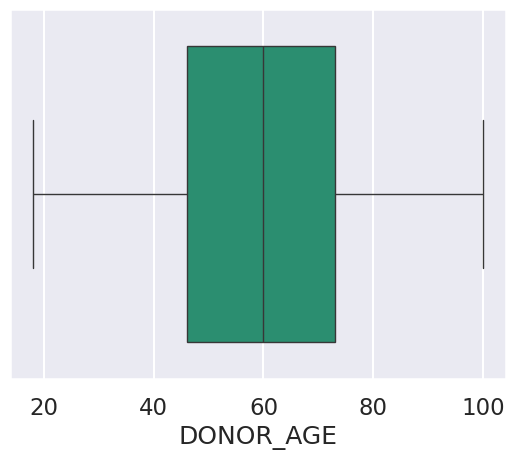

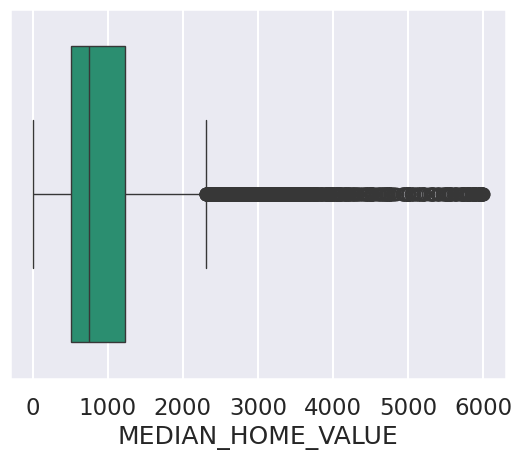

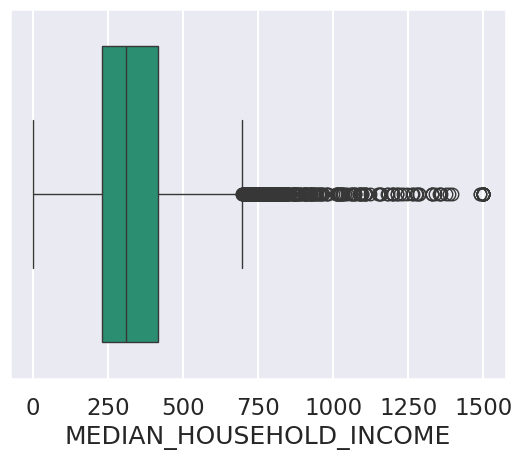

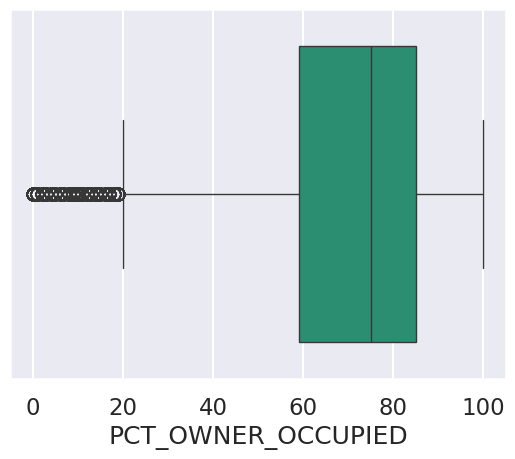

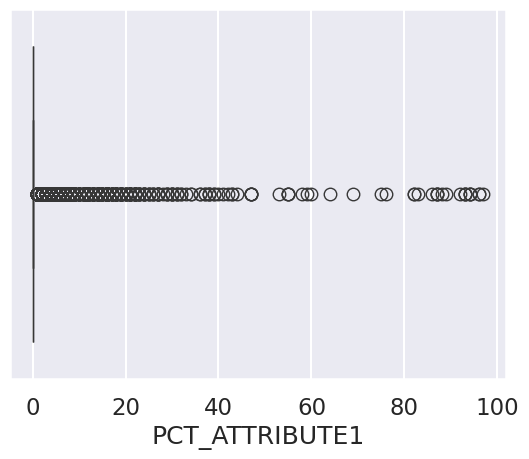

...

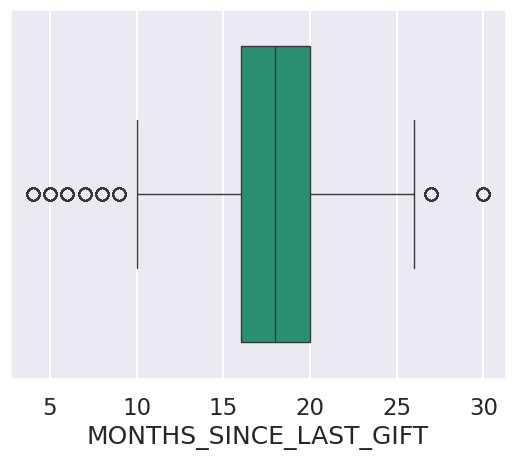

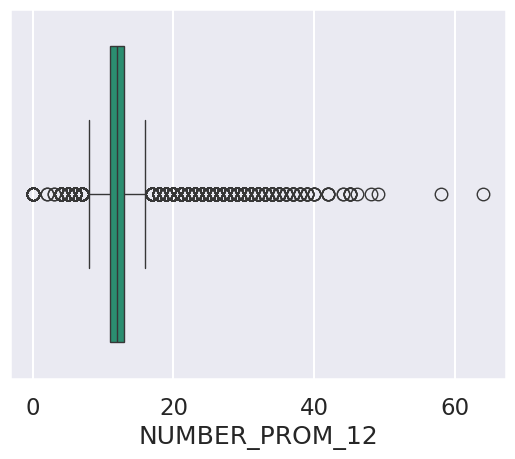

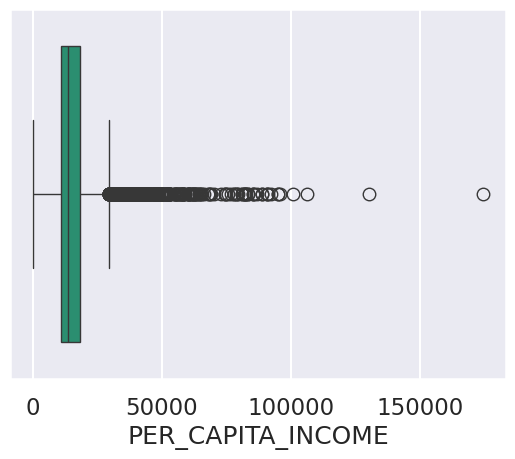

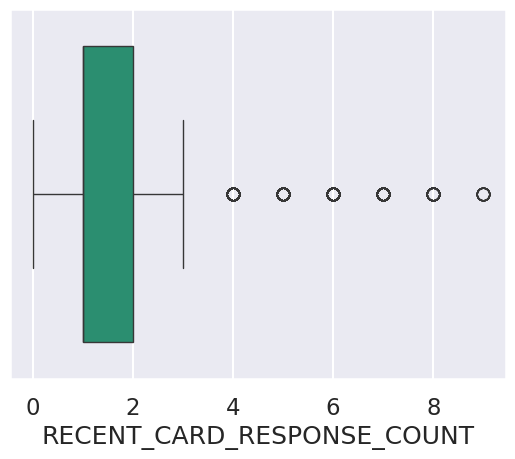

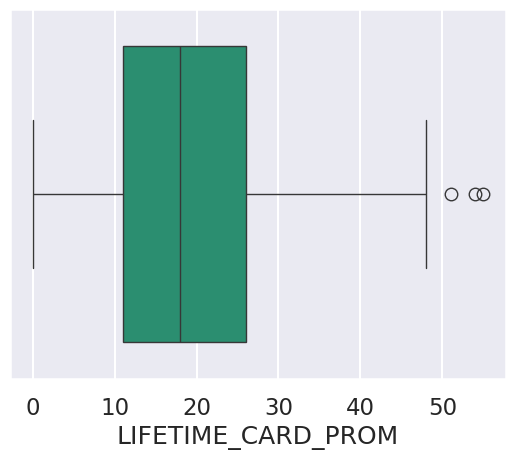

In [91]:
for i in tqdm(train_backup[metric_features2].columns):
    sns.boxplot(data = train_backup, x = i, palette = 'Dark2')
    plt.show()

  0%|          | 0/30 [00:00<?, ?it/s]

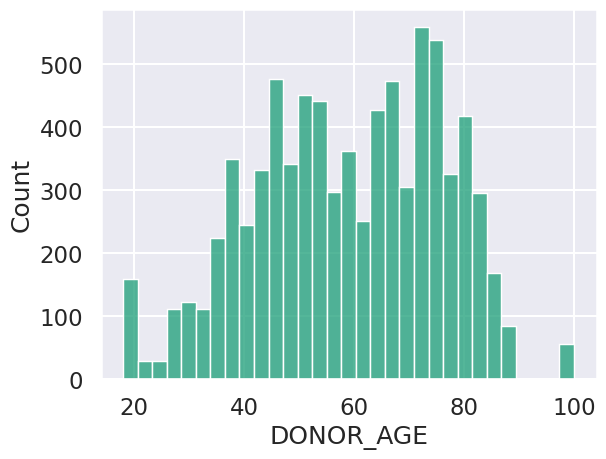

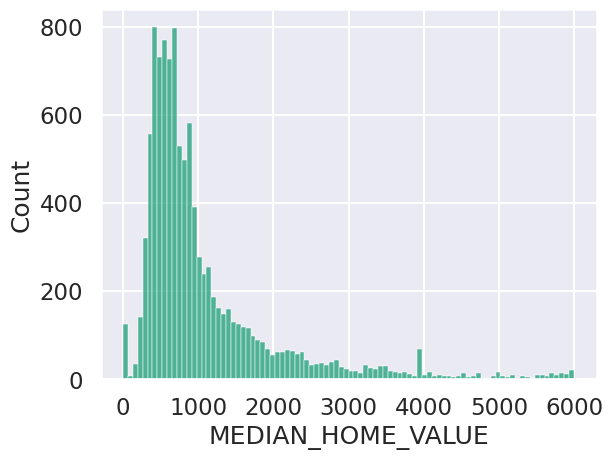

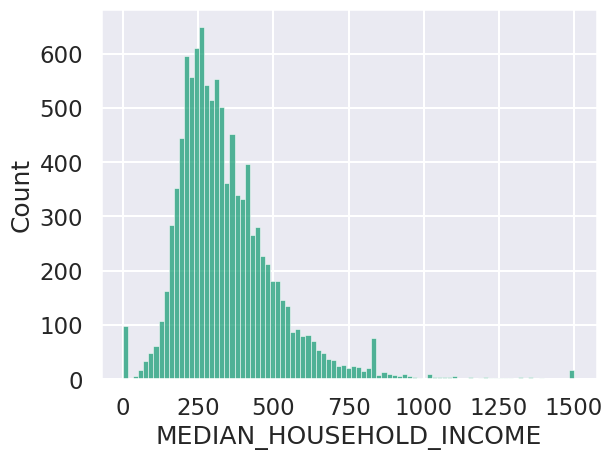

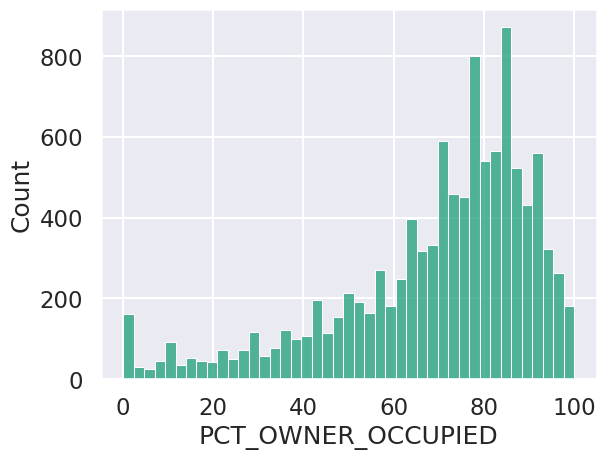

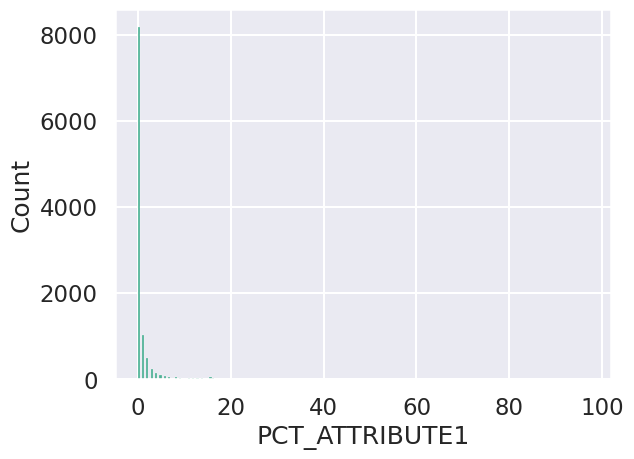

...

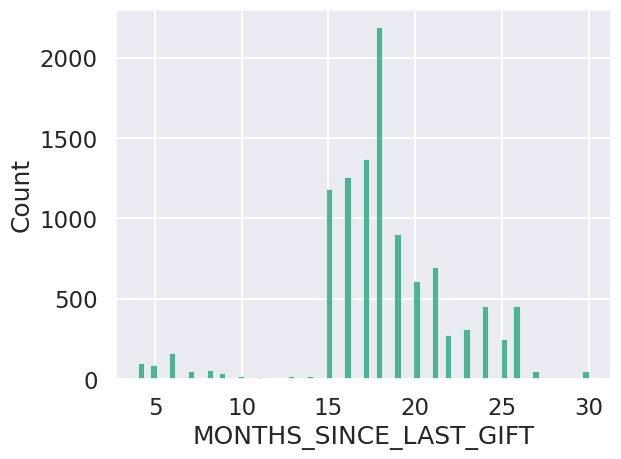

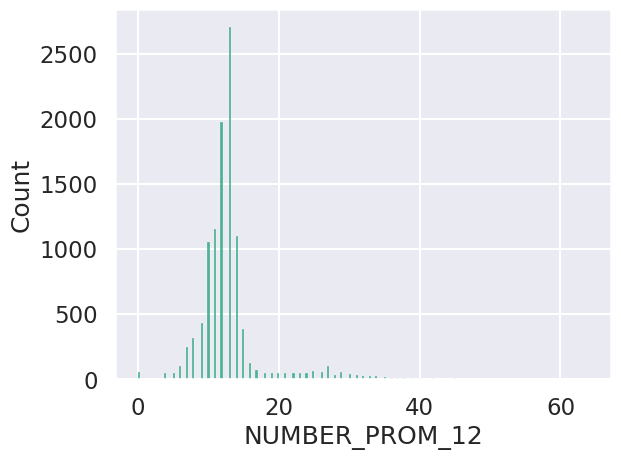

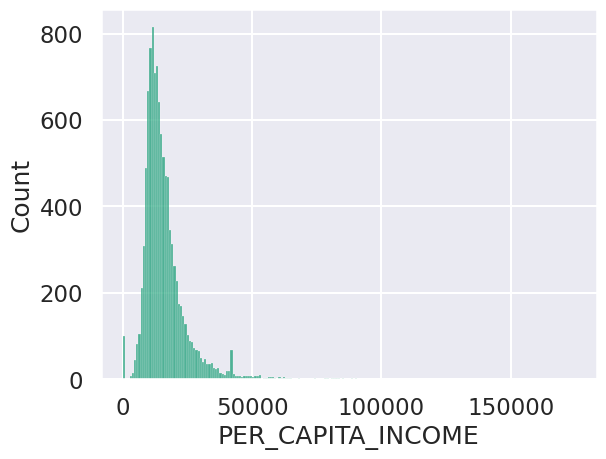

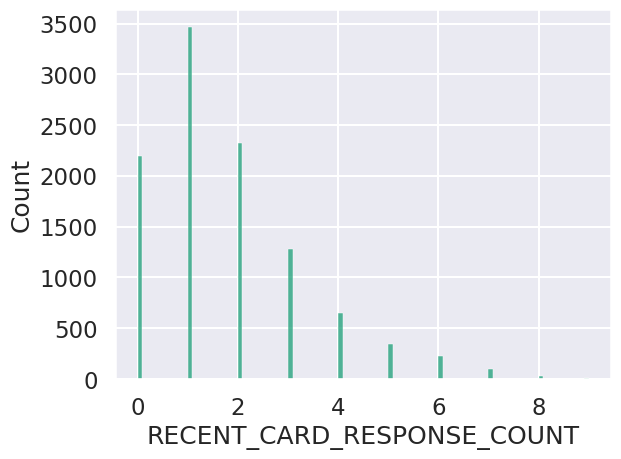

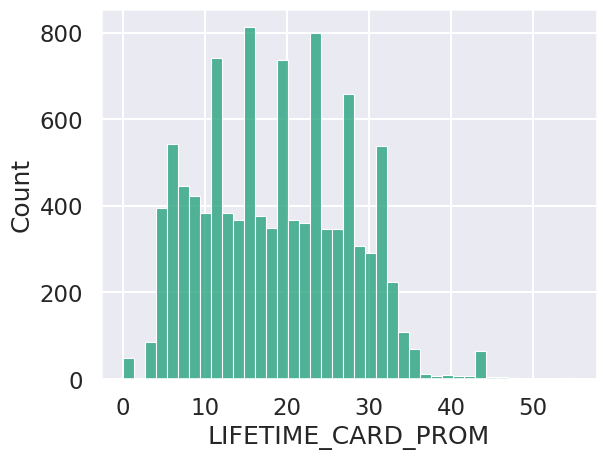

In [92]:
for i in tqdm(train_backup[metric_features2].columns):
  sns.histplot(data = train_backup, x = i, palette = 'Dark2')
  plt.show()

The most skewed variables are:

* `MEDIAN_HOME_VALUE`<br>
* `MEDIAN_HOUSEHOLD_INCOME`<br>

Variables like `PCT_OWNER_OCCUPIED`, `PCT_ATTRIBUTE1`, `PCT_ATTRIBUTE2`, `PCT_ATTRIBUTE3` and `PCT_ATTRIBUTE4`have a lot of outliers, but as we are dropping them in the future (in the feature selection phase) since we don't think they represent relevant information for our model, we are not going to treat them.

We are only going to treat 2 variables: `MEDIAN_HOME_VALUE` & `MEDIAN_HOUSEHOLD_INCOME` as they are the most skewed ones, applying a log transformation and deciding only to keep values greater than 0.

We consider that the other variables are comportamental variables, so their outliers are relevant information.

So, let's transform the most skewed variables by applying a Log transformation.

  0%|          | 0/8 [00:00<?, ?it/s]

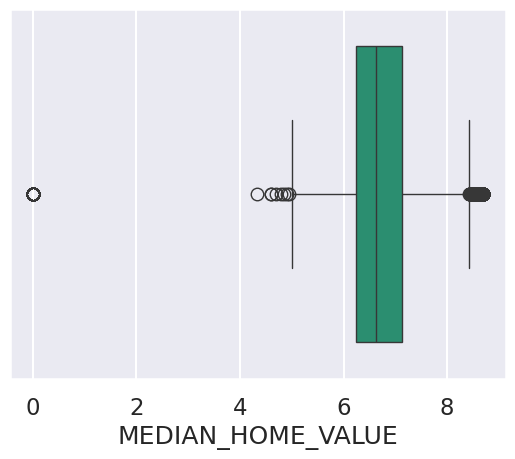

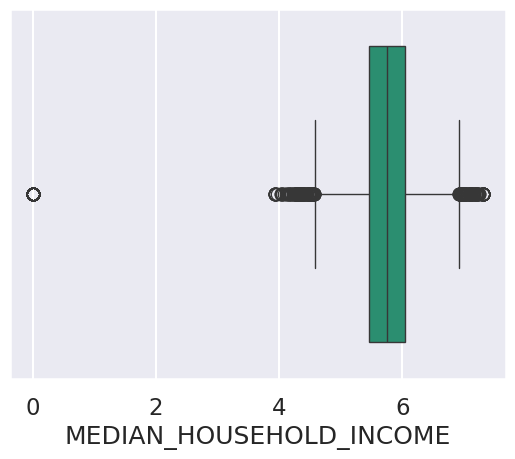

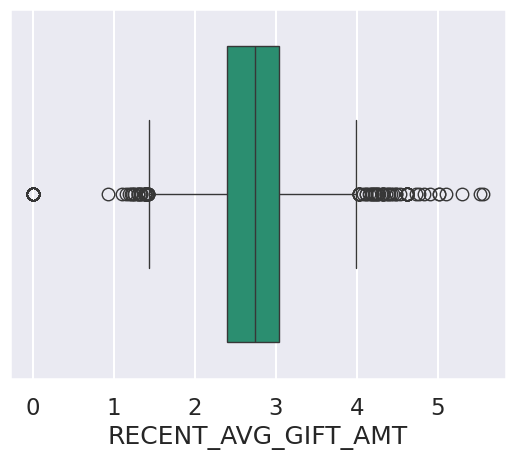

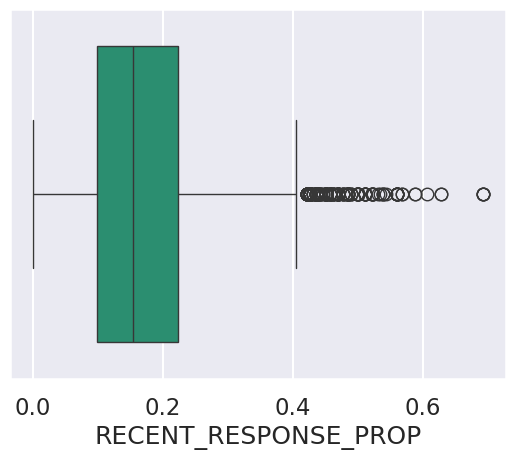

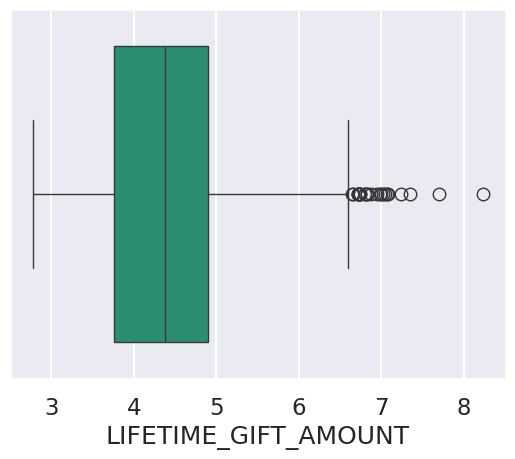

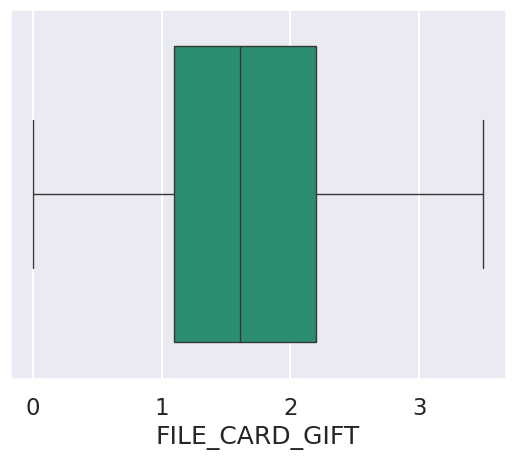

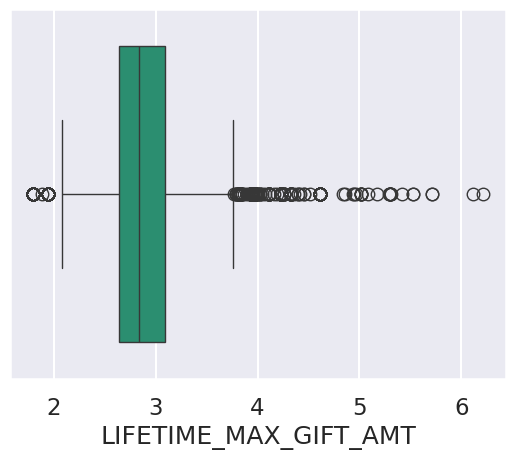

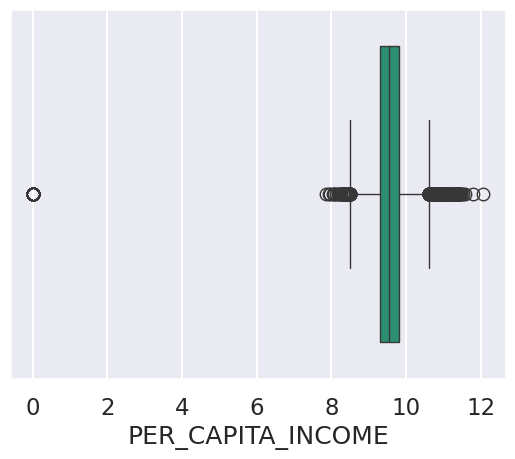

In [93]:
variables_to_transform = ['MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'RECENT_AVG_GIFT_AMT', "RECENT_RESPONSE_PROP", 'LIFETIME_GIFT_AMOUNT', "FILE_CARD_GIFT",'LIFETIME_MAX_GIFT_AMT', 'PER_CAPITA_INCOME' ]

for i in tqdm(variables_to_transform):


    train_backup[i] = np.log1p(train_backup[i])


    sns.boxplot(data = train_backup, x = i, palette = 'Dark2')
    plt.show()

  0%|          | 0/8 [00:00<?, ?it/s]

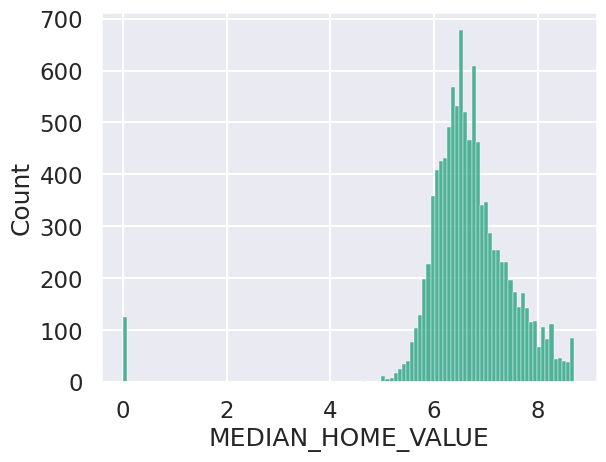

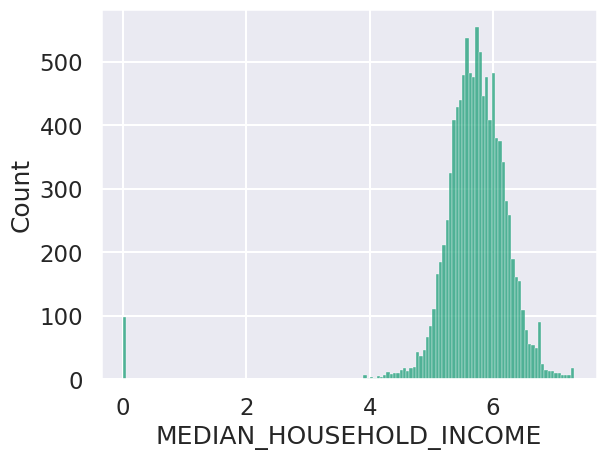

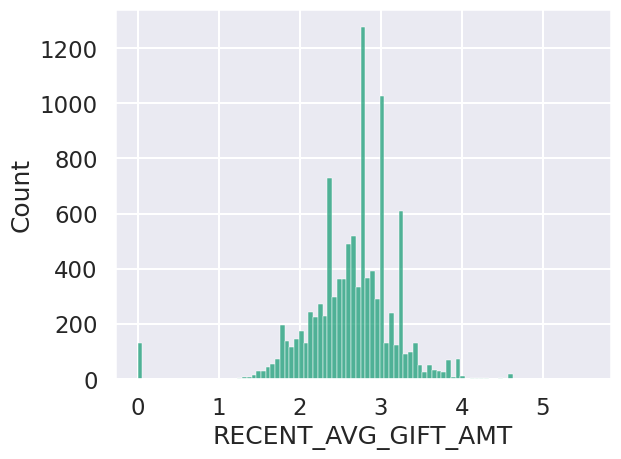

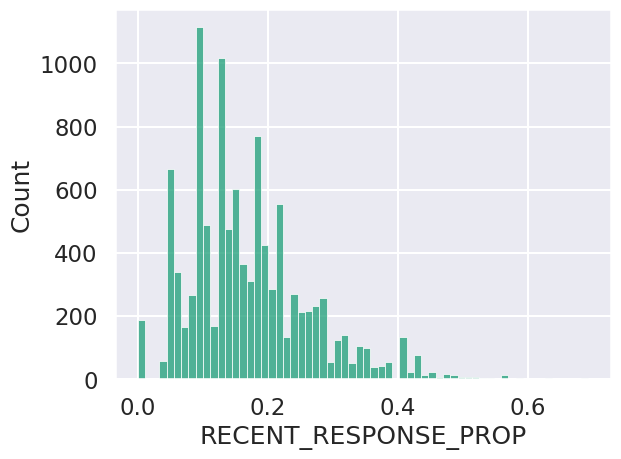

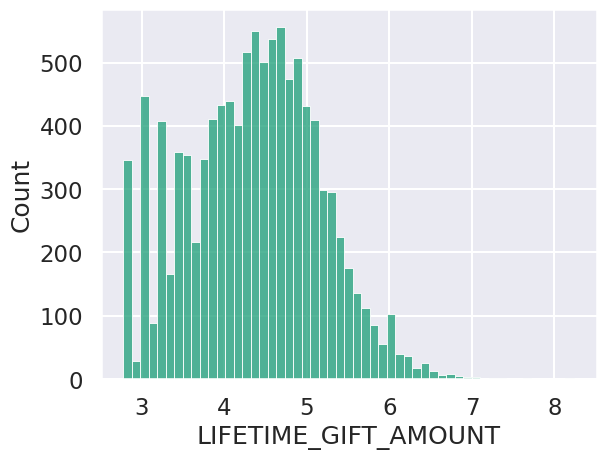

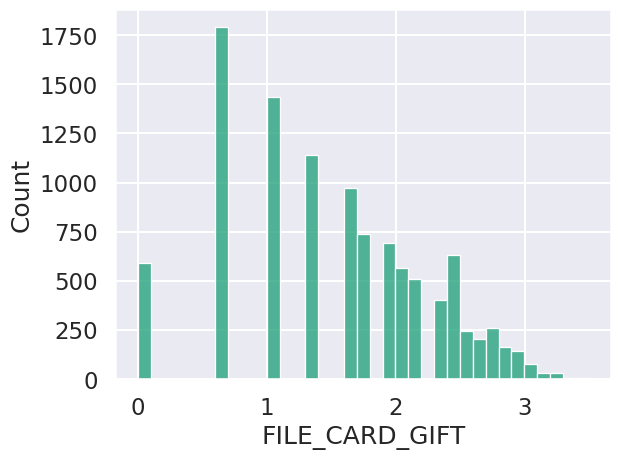

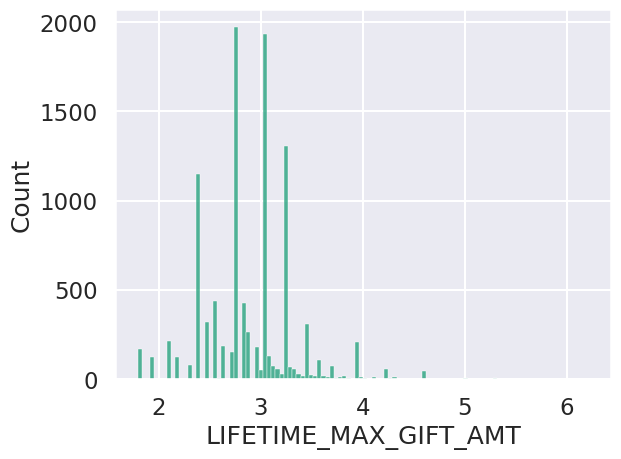

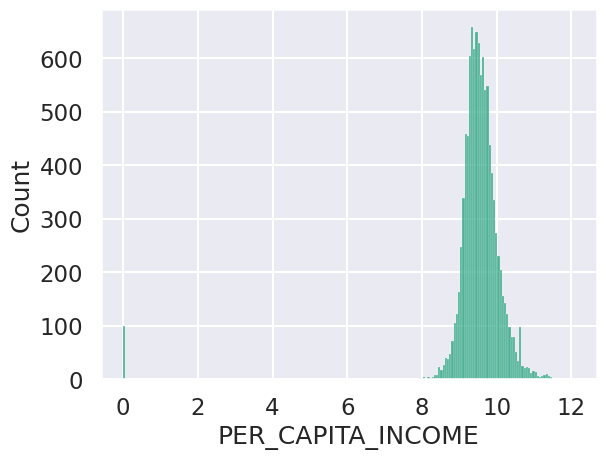

In [94]:
for i in tqdm(train_backup[['MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME','RECENT_AVG_GIFT_AMT', "RECENT_RESPONSE_PROP", 'LIFETIME_GIFT_AMOUNT', "FILE_CARD_GIFT", 'LIFETIME_MAX_GIFT_AMT', 'PER_CAPITA_INCOME']].columns):
  sns.histplot(data = train_backup, x = i, palette = 'Dark2')
  plt.show()

Let's check their boxplots again:

  0%|          | 0/8 [00:00<?, ?it/s]

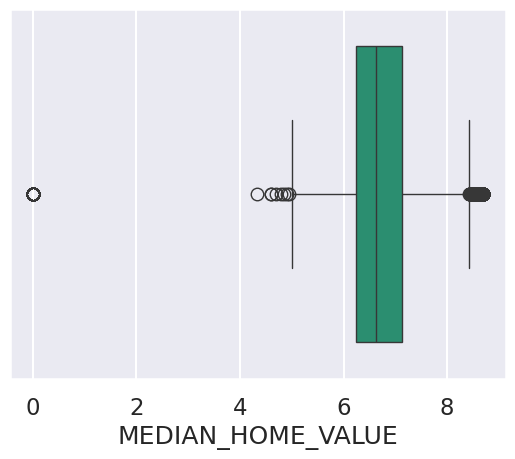

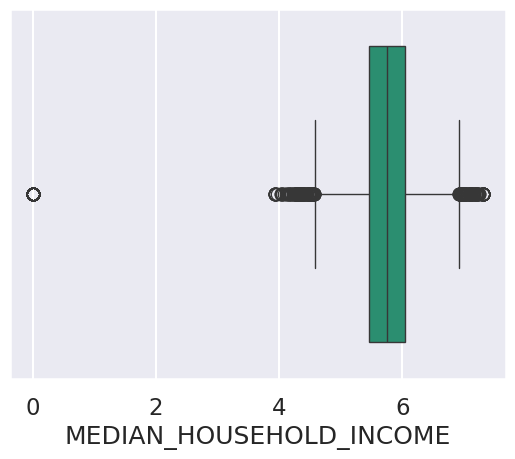

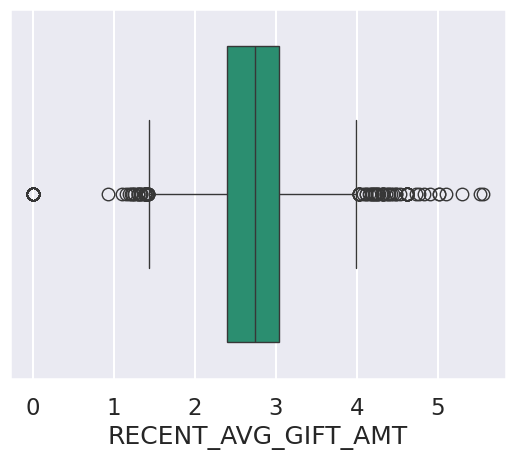

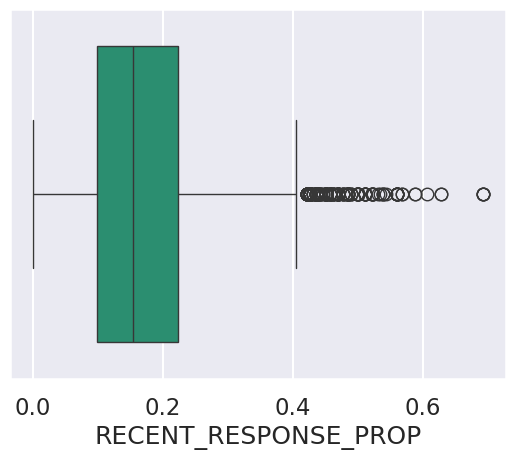

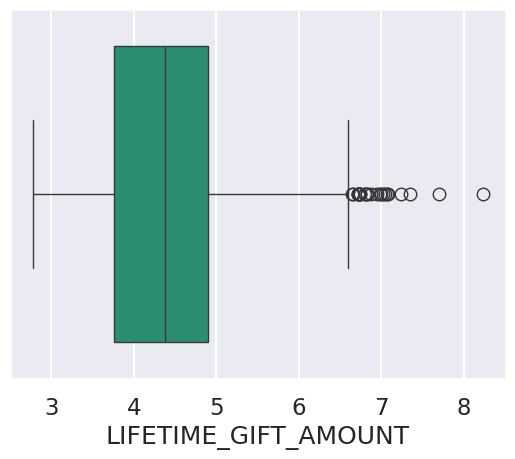

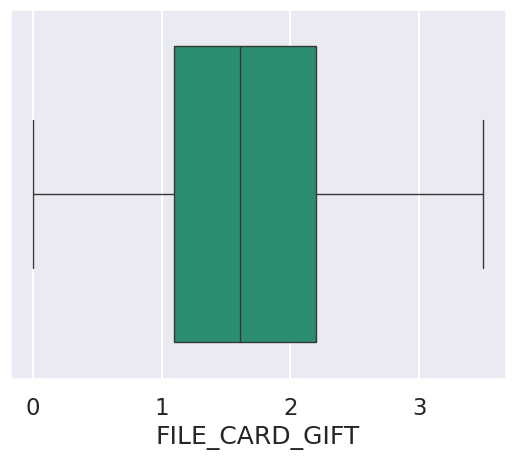

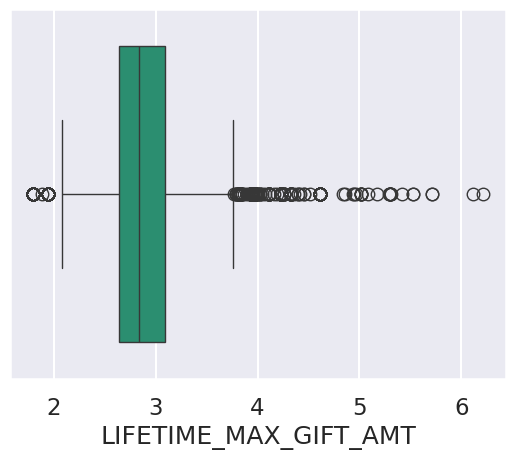

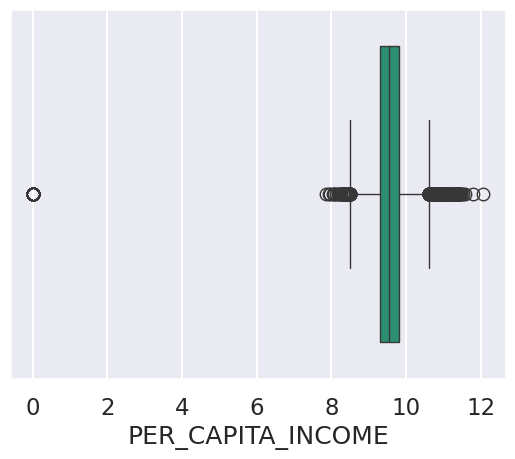

In [95]:
for i in tqdm(train_backup[['MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'RECENT_AVG_GIFT_AMT', "RECENT_RESPONSE_PROP", 'LIFETIME_GIFT_AMOUNT', "FILE_CARD_GIFT", 'LIFETIME_MAX_GIFT_AMT', 'PER_CAPITA_INCOME']].columns):
  sns.boxplot(data = train_backup, x = i, palette = 'Dark2')
  plt.show()

  0%|          | 0/30 [00:00<?, ?it/s]

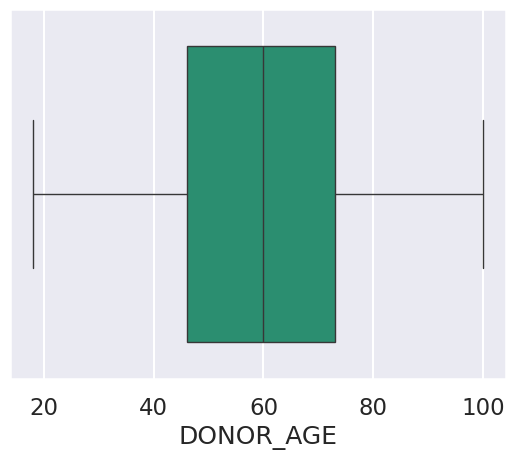

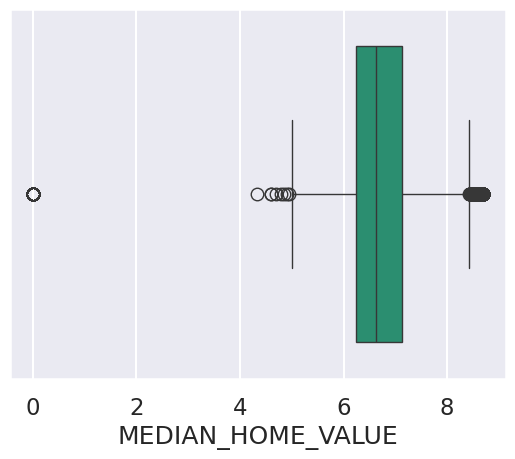

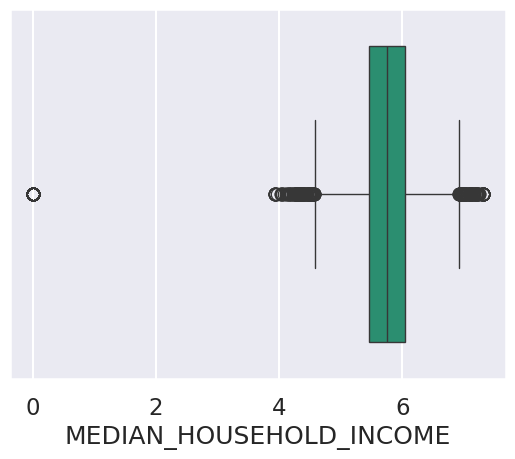

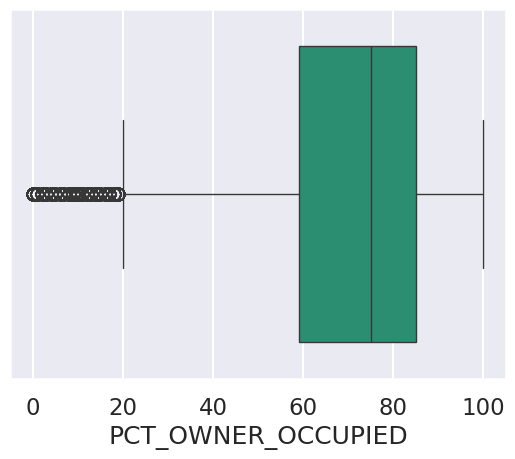

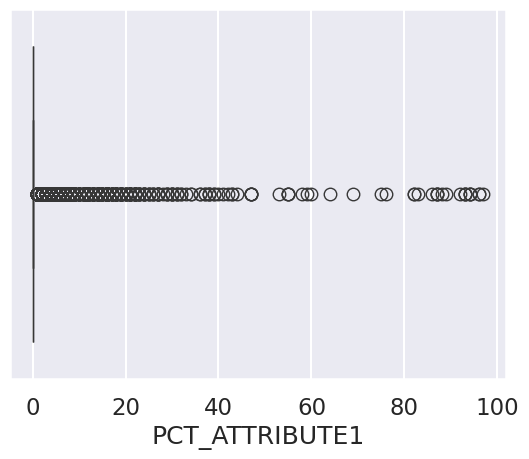

...

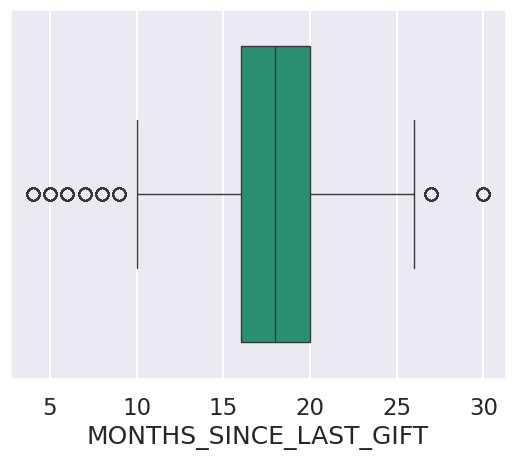

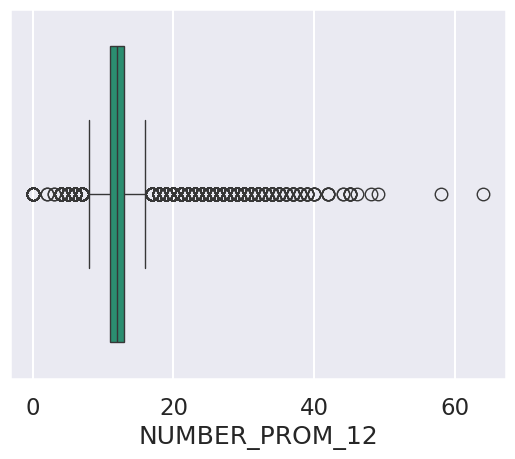

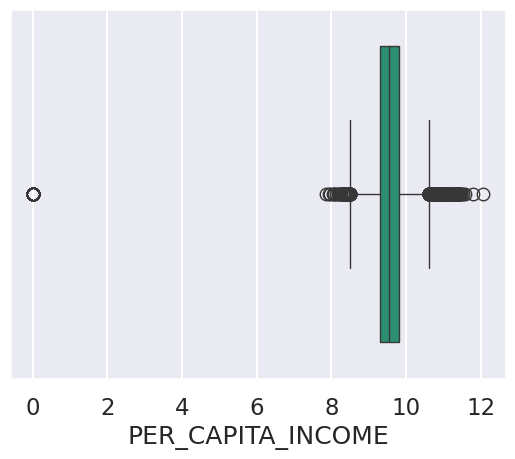

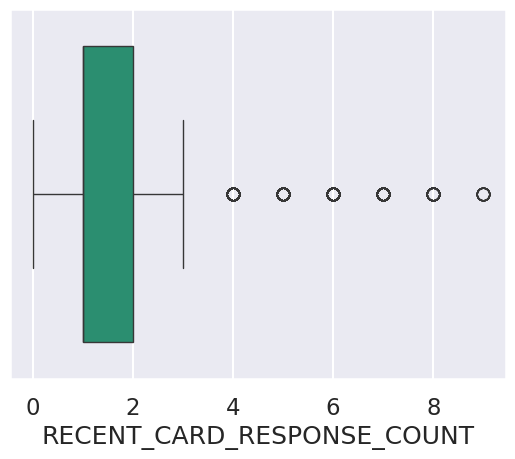

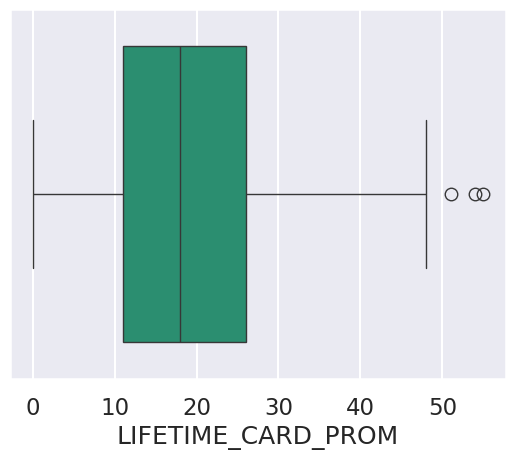

In [96]:
for i in tqdm(train_backup[metric_features2].columns):
  sns.boxplot(data = train_backup, x = i, palette = 'Dark2')
  plt.show()

In [97]:
cols_clip = ['LIFETIME_MIN_GIFT_AMT',
    'NUMBER_PROM_12',
    'LIFETIME_GIFT_COUNT',
    'LIFETIME_GIFT_AMOUNT',
    'LAST_GIFT_AMT'
]

# Store training bounds so validation uses the exact same thresholds
clip_bounds = {}
for col in cols_clip:
    lower = train_backup[col].quantile(0.01)
    upper = train_backup[col].quantile(0.99)
    clip_bounds[col] = (lower, upper)
    train_backup[col] = train_backup[col].clip(lower, upper)

  0%|          | 0/6 [00:00<?, ?it/s]

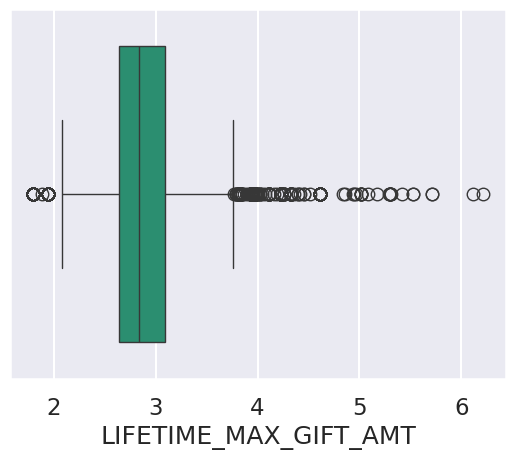

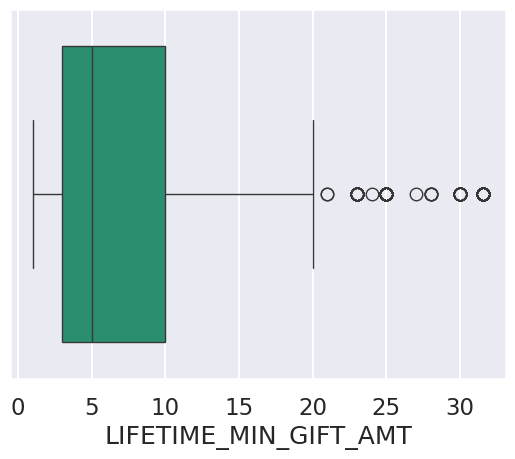

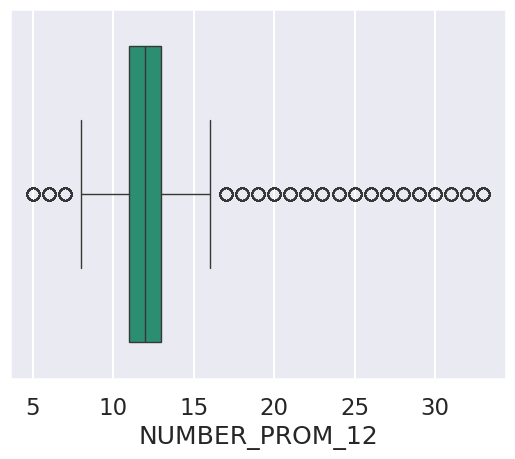

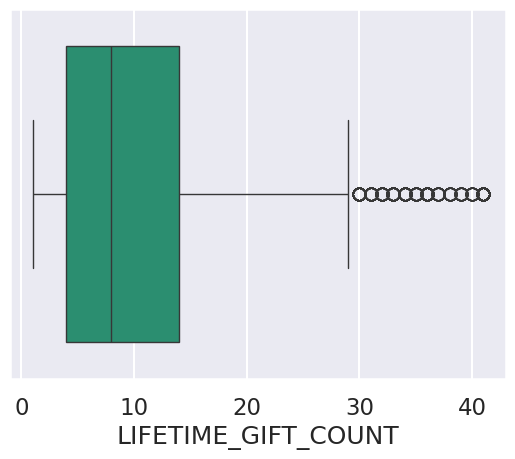

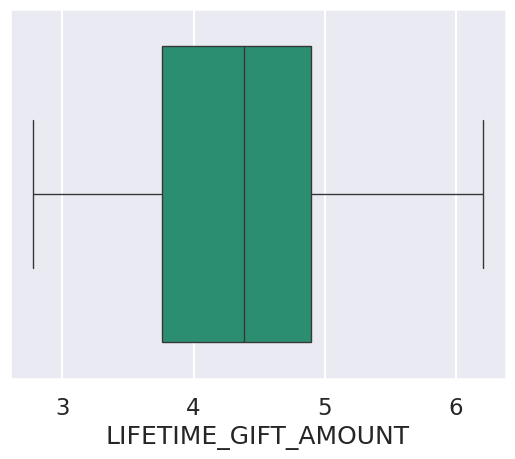

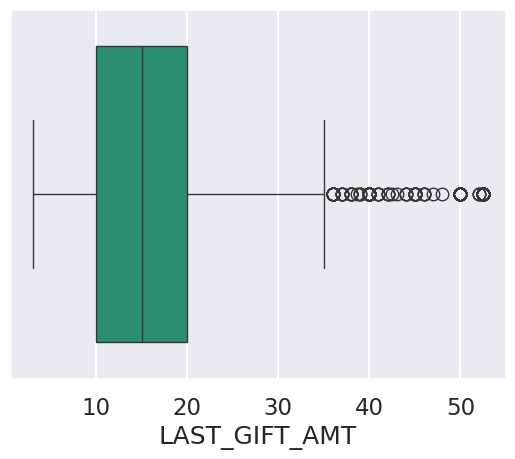

In [98]:
 for i in tqdm(train_backup[[ 'LIFETIME_MAX_GIFT_AMT',
    'LIFETIME_MIN_GIFT_AMT',
    'NUMBER_PROM_12',
    'LIFETIME_GIFT_COUNT',
    'LIFETIME_GIFT_AMOUNT',
    'LAST_GIFT_AMT']].columns):
  sns.boxplot(data = train_backup, x = i, palette = 'Dark2')
  plt.show()

In [99]:
(1 - len(train_backup)/len(train_df)) * 100

0.0

### 4.3 Missing Values

Addressing missing values is a critical step in data preprocessing, as it directly impacts the quality, reliability, and interpretability of any subsequent analysis or modeling.

Upon initial inspection, the donors DataFrame presented several columns with missing values.

Drop variables with high percentage of missing values

In [100]:
missing_counts = train_backup.isna().sum()
missing_percentages = (train_backup.isna().sum() / train_backup.shape[0]) * 100
total_rows = train_backup.shape[0]

missing_info = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentages,
    'Total Rows': total_rows
})

missing_info = missing_info.sort_values(by='Missing Count', ascending=False)

display(missing_info[missing_info['Missing Count'] > 0])

,Missing Count,Missing Percentage (%),Total Rows
WEALTH_RATING,5008,46.165192,10848
DONOR_AGE,2865,26.410398,10848
INCOME_GROUP,2647,24.400811,10848
DONOR_GENDER,775,7.144174,10848
URBANICITY,469,4.323378,10848
SES,465,4.286504,10848
MONTHS_SINCE_LAST_PROM_RESP,327,3.014381,10848
LIFETIME_MAX_GIFT_AMT,288,2.654867,10848
RECENT_AVG_GIFT_AMT,285,2.627212,10848
LIFETIME_GIFT_AMOUNT,271,2.498156,10848


In [101]:
train_backup.drop('INCOME_GROUP', axis = 1, inplace = True)

In [102]:
train_backup.drop('WEALTH_RATING', axis = 1, inplace = True)

The column with the most missing values is `DONOR_AGE` (26.47% missing). Despite its high missing percentage, DONOR_AGE is a crucial demographic factor in donor analysis. Therefore, instead of outright dropping the values were first clipped to a realistic range (18 to 100 years, as seen in Step 14) to correct illogical entries. The remaining missing values for DONOR_AGE are to imputed using K-NN later on.

The remaining variables in the dataset demonstrate a low incidence of missing values. The highest remaining missing percentage is found in `MONTHS_SINCE_LAST_PROM_RESP` at 3.17%, followed by `SES` with 2.11%. The majority of other columns, including `CHILDREN`, `FILE_CARD_GIFT`, and various `LIFETIME` and `RECENT` metrics, show missing value percentages consistently below 2.06%. This suggests that imputation methods would be effective in addressing these gaps without significantly altering the overall data distribution or introducing substantial bias.

To procede with our analysis, integer-like variables were converted to 'Int64' to maintain data integrity.

In [103]:
train_backup[['DONOR_AGE', 'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT', 'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT', 'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12', 'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'RECENT_CARD_RESPONSE_COUNT', 'LIFETIME_CARD_PROM', 'SES']] = train_backup[['DONOR_AGE', 'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT', 'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT', 'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12', 'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'RECENT_CARD_RESPONSE_COUNT','LIFETIME_CARD_PROM', 'SES']].astype('Int64')

**Categorical Features**: Missing values will be filled using the mode (the most frequent category).

In [104]:
categorical_features2 = ['DONOR_GENDER', 'SES', 'HOME_OWNER','PEP_STAR', 'RECENT_STAR_STATUS', 'RECENCY_STATUS_96NK', 'URBANICITY']

In [105]:
cat_modes = train_backup[categorical_features2].mode().iloc[0]
train_backup[categorical_features2] = train_backup[categorical_features2].fillna(cat_modes)

**Numerical Features**: Application of MinMaxScaler to normalize the variables range into a consistent format (0,1) to prevent distance measures from being dominated by one of the attributes. Then, KNNImputer will be used to fill the missing values, based on the nearest neighbours. The reason for this choice stems from the assumption that donors with similar numerical characteristics are likely to have similar missing values.

The **KNN Imputer** is a method for handling missing data by filling in missing values based on the k-nearest neighbors (KNN) of each data point. Here’s how it works:
1. Identify missing values in the dataset.
2. For each missing value, the imputer:
- Calculates the distance between the data point with the missing value and all other data points using a chosen distance metric (e.g., Euclidean distance).
- Selects the k-nearest neighbors based on this distance.
- The missing value is then filled in with the mean (or median) of the values from these k-nearest neighbors.

**Example:**
If a data point has a missing value and its 3 nearest neighbors have values of 10, 12, and 14 for that feature, the missing value will be imputed with the mean of these values, i.e., 12.


KNN uses distances, so, before using it, we will need to convert our data to the same range. We were always going to do this eventually - so might as well do it now.


In [106]:
# 2. Numerical Features: Fit Scaler & KNNImputer on TRAIN only (excluding TARGET_B!)
train_original = train_backup.copy()
num_cols = [c for c in train_original.select_dtypes(include=np.number).columns if c != 'TARGET_B']
train_num = train_original[num_cols].copy()

knn_scaler = MinMaxScaler()
train_scaled = knn_scaler.fit_transform(train_num)

knn_imputer = KNNImputer(n_neighbors=5)
train_imputed_scaled = knn_imputer.fit_transform(train_scaled)
train_imputed = knn_scaler.inverse_transform(train_imputed_scaled)

train_clean = train_original.copy()
train_clean[num_cols] = pd.DataFrame(train_imputed, columns=num_cols, index=train_original.index)

In [108]:
train_clean.info()
print("\n--- Explanation of Data Types ---")
print("As observed above:")
print("1. Dummy variables (e.g., 'DONOR_GENDER_M', 'URBANICITY_R', 'HOME_OWNER_U') were successfully created and are of 'bool' or binary type.")
print("2. Several columns that were previously converted to integer types (e.g., 'CHILDREN', 'FILE_CARD_GIFT') are now 'float64'.")
print("   This is because `MinMaxScaler` and `KNNImputer` were applied after the integer conversion. These operations normalize and impute values, converting numerical columns to floating-point numbers, which is standard behavior.")

<class 'pandas.core.frame.DataFrame'>
Index: 10848 entries, 151846 to 44945
Data columns (total 38 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CARD_PROM_12                 10848 non-null  float64
 1   CHILDREN                     10848 non-null  float64
 2   DONOR_AGE                    10848 non-null  float64
 3   DONOR_GENDER                 10848 non-null  object 
 4   FILE_CARD_GIFT               10848 non-null  float64
 5   FREQUENCY_STATUS_97NK        10848 non-null  float64
 6   HOME_OWNER                   10848 non-null  object 
 7   LAST_GIFT_AMT                10848 non-null  float64
 8   LIFETIME_CARD_PROM           10848 non-null  float64
 9   LIFETIME_GIFT_AMOUNT         10848 non-null  float64
 10  LIFETIME_GIFT_COUNT          10848 non-null  float64
 11  LIFETIME_MAX_GIFT_AMT        10848 non-null  float64
 12  LIFETIME_MIN_GIFT_AMT        10848 non-null  float64
 13  LIFETIME_PROM   

In [109]:
columns_to_int = [
    'DONOR_AGE', 'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT',
    'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT',
    'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12',
    'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'SES'
]

for col in columns_to_int:
    if col in train_clean.columns:
        # Round the values before converting to Int64 to avoid TypeErrors
        train_clean[col] = train_clean[col].round().astype('Int64')

print("Data types after converting to Int64:")
display(train_clean[columns_to_int].head())

Data types after converting to Int64:


,DONOR_AGE,CHILDREN,FREQUENCY_STATUS_97NK,FILE_CARD_GIFT,LIFETIME_PROM,RECENT_AVG_CARD_GIFT_AMT,RECENT_RESPONSE_COUNT,MONTHS_SINCE_LAST_PROM_RESP,LIFETIME_GIFT_COUNT,NUMBER_PROM_12,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_FIRST_GIFT,SES
CONTROL_NUMBER,,,,,,,,,,,,,
151846,55,4,4,1,19,4,3,15,4,14,15,21,1
1789,79,2,3,2,64,10,10,17,25,11,17,65,3
173523,30,0,1,1,51,20,2,21,5,13,21,56,1
123909,65,3,4,2,67,6,5,18,28,11,18,126,2
49812,60,1,4,3,73,4,11,19,41,10,19,126,3


In [110]:
train_clean

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,...,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,TARGET_B
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
151846,5.0,4,55,M,1,4,U,9.0,7.0,3.178054,...,4,1.897620,2.0,0.667,3,0.356975,0.0,1,S,1
1789,5.0,2,79,M,2,3,U,10.0,26.0,5.420535,...,10,2.397895,6.0,0.545,10,0.405465,1.0,3,C,0
173523,6.0,0,30,M,1,1,H,20.0,21.0,4.454347,...,20,3.044522,2.0,0.200,2,0.099845,0.0,1,S,0
123909,6.0,3,65,M,2,4,H,5.0,32.0,4.682131,...,6,2.054124,1.0,0.100,5,0.245296,1.0,2,C,1
49812,5.0,1,60,F,3,4,H,3.0,32.0,5.087596,...,4,1.591274,8.0,0.727,11,0.456792,1.0,3,R,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24809,6.0,3,51,F,1,2,H,12.0,12.0,3.761200,...,15,2.708050,2.0,0.250,3,0.154436,0.0,2,R,0
64671,4.0,0,45,F,1,1,H,10.0,24.0,5.049856,...,10,2.397895,1.0,0.000,2,0.105261,1.0,2,S,0
7134,6.0,2,72,M,1,2,H,10.0,29.0,5.583496,...,0,2.602690,0.0,0.000,2,0.097281,1.0,3,C,0


In [111]:
train_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10848 entries, 151846 to 44945
Data columns (total 38 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CARD_PROM_12                 10848 non-null  float64
 1   CHILDREN                     10848 non-null  Int64  
 2   DONOR_AGE                    10848 non-null  Int64  
 3   DONOR_GENDER                 10848 non-null  object 
 4   FILE_CARD_GIFT               10848 non-null  Int64  
 5   FREQUENCY_STATUS_97NK        10848 non-null  Int64  
 6   HOME_OWNER                   10848 non-null  object 
 7   LAST_GIFT_AMT                10848 non-null  float64
 8   LIFETIME_CARD_PROM           10848 non-null  float64
 9   LIFETIME_GIFT_AMOUNT         10848 non-null  float64
 10  LIFETIME_GIFT_COUNT          10848 non-null  Int64  
 11  LIFETIME_MAX_GIFT_AMT        10848 non-null  float64
 12  LIFETIME_MIN_GIFT_AMT        10848 non-null  float64
 13  LIFETIME_PROM   

### 4.4 Feature Engineering

In [112]:
train_clean['TOTAL_AVG_GIFT'] = train_clean['LIFETIME_GIFT_AMOUNT'] / train_clean['LIFETIME_GIFT_COUNT']

In [113]:
train_clean['RESPONSE_RATE'] = train_clean['RECENT_RESPONSE_COUNT'] / train_clean['NUMBER_PROM_12']

In [114]:
finite_bounds = {}
for col in train_clean.columns:
    if train_clean[col].dtype in ['Float64', 'float64']:
        max_finite = train_clean[col][np.isfinite(train_clean[col])].max()
        min_finite = train_clean[col][np.isfinite(train_clean[col])].min()
        max_val = max_finite if pd.notna(max_finite) else 0
        min_val = min_finite if pd.notna(min_finite) else 0
        finite_bounds[col] = (min_val, max_val)
        train_clean[col] = train_clean[col].replace([np.inf, -np.inf], [max_val, min_val])

In [115]:
train_clean['TOTAL_AVG_GIFT'] = train_clean['TOTAL_AVG_GIFT'].fillna(0)

In [116]:
train_clean['RESPONSE_RATE'] = train_clean['RESPONSE_RATE'].fillna(0)

### 4.5 Feature Selection (Numerical Variables)

In [117]:
metric_features3 = [ 'DONOR_AGE', 'MEDIAN_HOME_VALUE', 'MEDIAN_HOUSEHOLD_INCOME', 'PCT_OWNER_OCCUPIED', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4', 'CHILDREN', 'RECENT_AVG_GIFT_AMT', 'RECENT_CARD_RESPONSE_PROP', 'FREQUENCY_STATUS_97NK', 'RECENT_RESPONSE_PROP', 'FILE_CARD_GIFT', 'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT', 'MONTHS_SINCE_LAST_PROM_RESP', "CARD_PROM_12", "LAST_GIFT_AMT", "LIFETIME_GIFT_AMOUNT", "LIFETIME_GIFT_COUNT", "LIFETIME_MAX_GIFT_AMT", "LIFETIME_MIN_GIFT_AMT", "MONTHS_SINCE_FIRST_GIFT", "MONTHS_SINCE_LAST_GIFT", "NUMBER_PROM_12" , 'PER_CAPITA_INCOME', 'RECENT_CARD_RESPONSE_COUNT', 'LIFETIME_CARD_PROM', 'TOTAL_AVG_GIFT', 'RESPONSE_RATE']

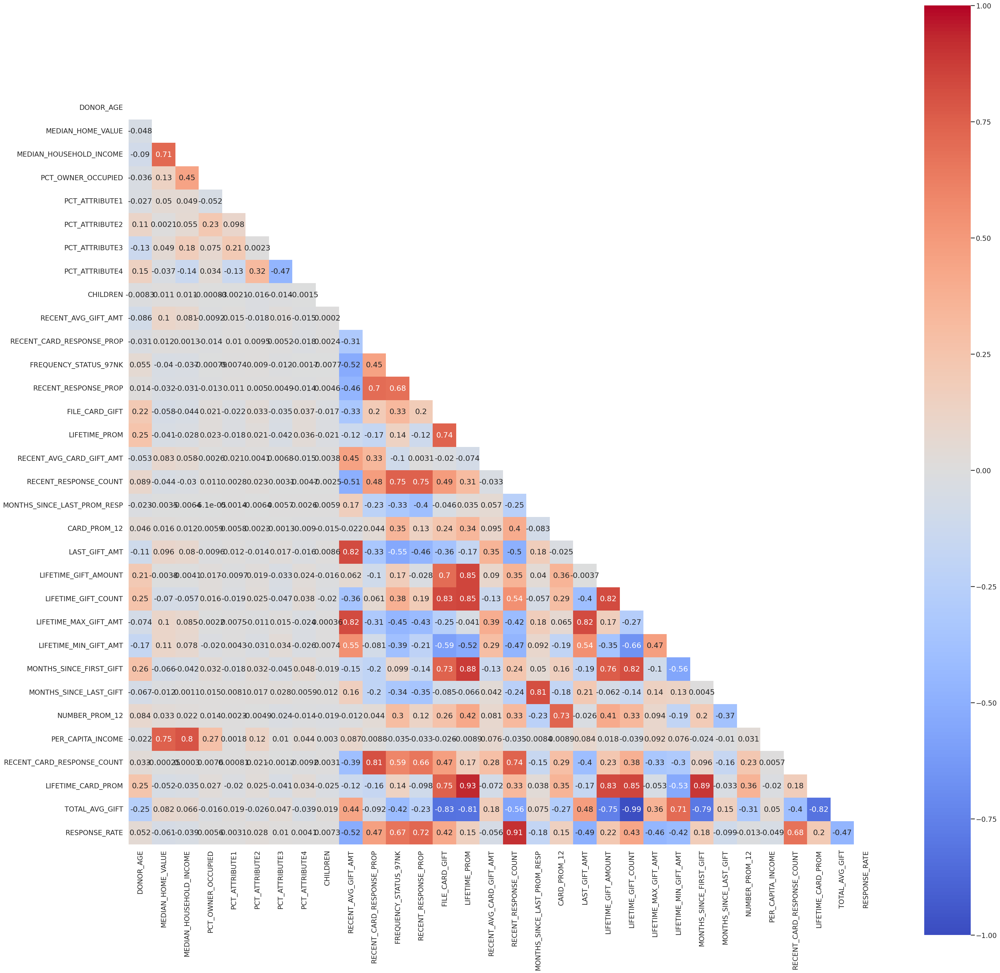

In [118]:
mask = np.zeros_like(train_clean[metric_features3].corr("spearman"))
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(40,40))
    ax = sns.heatmap(train_clean[metric_features3].corr("spearman"),mask=mask, annot = True,cmap='coolwarm',square=True,vmin=-1, vmax=1)

Highly correlated variables:

`PER_CAPITA_INCOME` & `MEDIAN_HOUSEHOLD_INCOME`

`LIFETIME_GIFT_AMOUNT` & `RECENT_AVG_GIFT_AMT`

`LIFETIME_MAX_GIFT_AMT` & `RECENT_AVG_GIFT_AMT`

`RECENT_CARD_RESPONDE_COUNT` & `RECENT_CARD_RESPONDE_PROP`

`LIFETIME_GIFT_COUNT` & `FILE_CARD_GIFT`

`LIFETIME_GIFT_AMOUNT` & `LIFETIME_PROM`

`LIFETIME_GIFT_COUNT` & `LIFETIME_PROM`

`MONTHS_SINCE_FIRST_GIFT` & `LIFETIME_PROM`

`TOTAL_AVG_GIFT` & `LIFETIME_PROM`

`TOTAL_AVG_GIFT` & `FILE_CARD_GIFT`

(`RECENT_CARD_RESPONSE_COUNT` & `RESPONSE_RATE`)

`MONTHS_SINCE_LAST_GIFT` & `MONTHS_SINCE_LAST_PROM_RESP`

`LIFETIME_MAX_GIFT_AMT` & `LAST_GIFT_AMT`

`LIFETIME_GIFT_COUNT` & `LIFETIME_GIFT_AMOUNT`

`LIFETIME_CARD_PROM` & `LIFETIME_GIFT_AMOUNT`

`MONTHS_SINCE_FIRST_GIFT` & `LIFETIME_GIFT_COUNT`

`LIFETIME_CARD_PROM` & `LIFETIME_GIFT_COUNT`

(`TOTAL_AVG_GIFT` & `LIFETIME_GIFT_COUNT`)

`LIFETIME_CARD_RPOM` & `MONTHS_SINCE_FIRST_GIFT`

`TOTAL_AVG_GIFT` & `MONTHS_SINCE_FIRST_GIFT`

`TOTAL_AVG_GIFT` & `LIFETIME_CARD_PROM`

LIFETIME_GIFT_COUNT, LIFETIME_PROM, MONTHS_SINCE_FIRST_GIFT, LIFETIME_GIFT_AMOUNT. TOTAL_AVG_GIFT

### 4.6 Feature Selection (Categorical Variables)

In [119]:
from scipy.stats import chi2_contingency
import pandas as pd

# Target variable
target_col = 'TARGET_B'


# Remove target from categorical list if needed
if target_col in categorical_features2:
    categorical_features2.remove(target_col)

chi2_results = []

for col in categorical_features2:

    # Create contingency table
    contingency_table = pd.crosstab(train_clean[col], train_clean[target_col])

    # Apply Chi-Square test
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    chi2_results.append({
        'Feature': col,
        'Chi2 Statistic': chi2,
        'p-value': p_value,
        'Degrees of Freedom': dof
    })

# Convert results to dataframe
chi2_results_df = pd.DataFrame(chi2_results)

# Sort by p-value
chi2_results_df = chi2_results_df.sort_values(by='p-value')

chi2_results_df

,Feature,Chi2 Statistic,p-value,Degrees of Freedom
3,PEP_STAR,117.374420,2.376827e-27,1
5,RECENCY_STATUS_96NK,117.672537,9.763129e-24,5
4,RECENT_STAR_STATUS,59.127512,1.477786e-14,1
1,SES,23.350907,3.412209e-05,3
6,URBANICITY,15.303876,4.110729e-03,4
2,HOME_OWNER,6.069871,1.375070e-02,1
0,DONOR_GENDER,0.086816,7.682651e-01,1


### 4.7 Encoding

To prepare categorical variables for the imputation method, they will be converted into numerical format using one-hot encoding. This creates new binary columns for each unique category within a feature.

In [120]:
cat_data1 = train_clean[['DONOR_GENDER', 'URBANICITY', "HOME_OWNER", 'RECENCY_STATUS_96NK']].copy()

In [122]:
dummy1 = pd.get_dummies(cat_data1, drop_first = True)
dummy1.head()

,DONOR_GENDER_M,URBANICITY_R,URBANICITY_S,URBANICITY_T,URBANICITY_U,HOME_OWNER_U,RECENCY_STATUS_96NK_E,RECENCY_STATUS_96NK_F,RECENCY_STATUS_96NK_L,RECENCY_STATUS_96NK_N,RECENCY_STATUS_96NK_S
CONTROL_NUMBER,,,,,,,,,,,
151846,True,False,True,False,False,True,False,False,False,True,False
1789,True,False,False,False,False,True,False,False,False,False,False
173523,True,False,True,False,False,False,False,False,False,False,False
123909,True,False,False,False,False,False,False,False,False,False,True
49812,False,True,False,False,False,False,False,False,False,False,True


In [123]:
train_clean = pd.concat([train_clean, dummy1], axis=1)

In [124]:
train_clean.drop('DONOR_GENDER', axis = 1, inplace = True)

In [126]:
train_clean.drop('HOME_OWNER', axis = 1, inplace = True)

KeyError: "['HOME_OWNER'] not found in axis"

In [127]:
train_clean.drop('URBANICITY', axis = 1, inplace = True)

In [128]:
train_clean.drop('RECENCY_STATUS_96NK', axis = 1, inplace = True)

After the transformations, the original categorical columns will be dropped, and the boolean values resulting from the creation of dummy variables will be converted to binary (0,1) for consistency.

In [129]:
train_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10848 entries, 151846 to 44945
Data columns (total 47 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CARD_PROM_12                 10848 non-null  float64
 1   CHILDREN                     10848 non-null  Int64  
 2   DONOR_AGE                    10848 non-null  Int64  
 3   FILE_CARD_GIFT               10848 non-null  Int64  
 4   FREQUENCY_STATUS_97NK        10848 non-null  Int64  
 5   LAST_GIFT_AMT                10848 non-null  float64
 6   LIFETIME_CARD_PROM           10848 non-null  float64
 7   LIFETIME_GIFT_AMOUNT         10848 non-null  float64
 8   LIFETIME_GIFT_COUNT          10848 non-null  Int64  
 9   LIFETIME_MAX_GIFT_AMT        10848 non-null  float64
 10  LIFETIME_MIN_GIFT_AMT        10848 non-null  float64
 11  LIFETIME_PROM                10848 non-null  Int64  
 12  MEDIAN_HOME_VALUE            10848 non-null  float64
 13  MEDIAN_HOUSEHOLD

In [130]:
train_clean[dummy1.columns] = train_clean[dummy1.columns].replace({True: 1, False: 0})

You can verify the data types by checking `train_clean.info()` again if needed. The values should now reflect the `Int64` type where applicable.

In [131]:
train_clean

,CARD_PROM_12,CHILDREN,DONOR_AGE,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,...,URBANICITY_R,URBANICITY_S,URBANICITY_T,URBANICITY_U,HOME_OWNER_U,RECENCY_STATUS_96NK_E,RECENCY_STATUS_96NK_F,RECENCY_STATUS_96NK_L,RECENCY_STATUS_96NK_N,RECENCY_STATUS_96NK_S
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
151846,5.0,4,55,1,4,9.0,7.0,3.178054,4,2.302585,...,0,1,0,0,1,0,0,0,1,0
1789,5.0,2,79,2,3,10.0,26.0,5.420535,25,2.397895,...,0,0,0,0,1,0,0,0,0,0
173523,6.0,0,30,1,1,20.0,21.0,4.454347,5,3.044522,...,0,1,0,0,0,0,0,0,0,0
123909,6.0,3,65,2,4,5.0,32.0,4.682131,28,2.639057,...,0,0,0,0,0,0,0,0,0,1
49812,5.0,1,60,3,4,3.0,32.0,5.087596,41,1.945910,...,1,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24809,6.0,3,51,1,2,12.0,12.0,3.761200,3,3.044522,...,1,0,0,0,0,0,0,0,0,0
64671,4.0,0,45,1,1,10.0,24.0,5.049856,15,2.772589,...,0,1,0,0,0,0,0,0,0,0
7134,6.0,2,72,1,2,10.0,29.0,5.583496,18,3.806662,...,0,0,0,0,0,0,0,0,0,0


### 4.8 Scaling the data

In [132]:
scaler = MinMaxScaler().fit(train_clean)
minmax_train = scaler.transform(train_clean)

In [133]:
train_clean = pd.DataFrame(minmax_train, columns = train_clean.columns, index = train_clean.index)

### 4.9 Final Feature Selection

In [134]:
train_selected = train_clean.copy()

In [135]:
train_selected.drop('LIFETIME_PROM', axis = 1, inplace = True)

In [136]:
train_selected.drop('LIFETIME_GIFT_COUNT', axis = 1, inplace = True)

In [137]:
train_selected.drop('MONTHS_SINCE_FIRST_GIFT', axis = 1, inplace = True)

In [138]:
train_selected.drop('LIFETIME_GIFT_AMOUNT', axis = 1, inplace = True)

In [139]:
train_selected.drop('TOTAL_AVG_GIFT', axis = 1, inplace = True)

In [140]:
train_selected.drop('RECENT_RESPONSE_COUNT', axis = 1, inplace = True)

In [141]:
train_selected.drop('NUMBER_PROM_12', axis = 1, inplace = True)

In [142]:
train_selected.drop('DONOR_GENDER_M', axis = 1, inplace = True)

# 5.Data Preprocessing (Validation Set)

In [143]:
val_backup = val_df.copy()

### 5.1 Incoherence Treatment

In [144]:
val_backup['DONOR_GENDER'] = val_backup['DONOR_GENDER'].replace('U', np.nan)
val_backup['SES'] = val_backup['SES'].replace('?', np.nan)
val_backup['URBANICITY'] = val_backup['URBANICITY'].replace('?', np.nan)
val_backup.loc[
    (val_backup['RECENT_STAR_STATUS'] < 0) |
    (val_backup['RECENT_STAR_STATUS'] > 1),
    'RECENT_STAR_STATUS'
] = 1

In [145]:
val_backup['PEP_STAR'] = val_backup['PEP_STAR'].clip(0, 1)

In [146]:
cols_pct = [
    'PCT_OWNER_OCCUPIED',
    'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2',
    'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4'
]

for col in cols_pct:
    val_backup[col] = val_backup[col].clip(0, 100)

In [147]:
cols_prop = [
    'RECENT_CARD_RESPONSE_PROP',
    'RECENT_RESPONSE_PROP'
]

for col in cols_prop:
    val_backup[col] = val_backup[col].clip(0, 1)

In [149]:
val_backup['DONOR_AGE'] = val_backup['DONOR_AGE'].clip(18, 100)

In [150]:
cols_non_negative = [
    'MEDIAN_HOME_VALUE', 'RECENT_AVG_GIFT_AMT',
    'LIFETIME_GIFT_AMOUNT', 'LIFETIME_MAX_GIFT_AMT',
    'LIFETIME_MIN_GIFT_AMT', 'LAST_GIFT_AMT', 'PER_CAPITA_INCOME', 'MEDIAN_HOUSEHOLD_INCOME'
]

for col in cols_non_negative:
    val_backup.loc[val_backup[col] < 0, col] = np.nan

In [151]:
cols_int = [
    'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT',
    'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT',
    'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12',
    'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'RECENT_CARD_RESPONSE_COUNT'
]

for col in cols_int:
    val_backup[col] = val_backup[col].clip(lower=0).round().astype('Int64')

In [152]:
val_backup.describe()

,CARD_PROM_12,CHILDREN,DONOR_AGE,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,...,PER_CAPITA_INCOME,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,WEALTH_RATING,TARGET_B
count,2651.000000,2657.0,1987.000000,2664.0,2659.0,2072.000000,2644.000000,2656.000000,2645.000000,2660.0,...,2653.000000,2657.0,2654.000000,2655.0,2662.000000,2666.0,2672.000000,2659.000000,1451.000000,2712.000000
mean,5.398569,2.084306,59.136890,5.397147,1.989846,3.922388,16.908683,18.734163,109.025266,10.233083,...,16311.700673,12.080918,15.592651,1.761205,0.236677,3.069017,0.191105,0.328319,5.132445,0.250000
std,1.298163,1.450373,17.350117,4.673807,1.111322,1.980353,11.646375,9.008749,113.537618,9.027547,...,8594.108090,11.429946,10.823029,1.552231,0.193005,2.066738,0.116490,0.469690,3.019833,0.433093
min,1.000000,0.0,18.000000,0.0,0.0,-1.728999,0.000000,-7.188999,15.000000,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,-3.751835,0.000000
25%,5.000000,1.0,46.500000,2.0,1.0,2.000000,10.000000,11.000000,42.000000,4.0,...,11176.000000,5.0,10.000000,1.0,0.100000,2.0,0.111000,0.000000,3.000000,0.000000
50%,6.000000,2.0,60.000000,4.0,2.0,4.000000,15.000000,18.500000,82.000000,8.0,...,14335.000000,10.0,14.250000,1.0,0.200000,3.0,0.167000,0.000000,5.000000,0.000000
75%,6.000000,3.0,73.000000,8.0,3.0,5.000000,20.000000,26.000000,135.000000,14.0,...,18892.000000,16.0,20.000000,3.0,0.364000,4.0,0.250000,1.000000,8.000000,0.250000
max,15.000000,6.0,100.000000,29.0,5.0,9.490799,201.670000,55.000000,2604.500000,69.0,...,100528.000000,212.0,201.670000,9.0,1.000000,13.0,1.000000,1.000000,13.446890,1.000000


### 5.2 Missing Values

In [153]:
# 1. Apply outlier clipping bounds learned from train_backup
for col, (lower, upper) in clip_bounds.items():
    val_backup[col] = val_backup[col].clip(lower, upper)

# 2. Fill missing categorical values using modes learned from train_backup
val_backup[categorical_features2] = val_backup[categorical_features2].fillna(cat_modes)

# 3. Transform numerical features using knn_scaler and knn_imputer fitted on TRAIN (.transform ONLY!)
val_original = val_backup.copy()
val_num = val_original[num_cols].copy()

val_backup.drop(['INCOME_GROUP', 'WEALTH_RATING'], axis=1, inplace=True)

val_scaled = knn_scaler.transform(val_num)
val_imputed_scaled = knn_imputer.transform(val_scaled)
val_imputed = knn_scaler.inverse_transform(val_imputed_scaled)

val_clean = val_original.copy()
val_clean[num_cols] = pd.DataFrame(val_imputed, columns=num_cols, index=val_original.index)

### 5.3 Feature Engineering

In [154]:
val_clean['TOTAL_AVG_GIFT'] = val_clean['LIFETIME_GIFT_AMOUNT'] / val_clean['LIFETIME_GIFT_COUNT']
val_clean['RESPONSE_RATE'] = val_clean['RECENT_RESPONSE_COUNT'] / val_clean['NUMBER_PROM_12']

# Replace infinities using finite_bounds learned from TRAIN
for col, (min_val, max_val) in finite_bounds.items():
    if col in val_clean.columns:
        val_clean[col] = val_clean[col].replace([np.inf, -np.inf], [max_val, min_val])

val_clean['TOTAL_AVG_GIFT'] = val_clean['TOTAL_AVG_GIFT'].fillna(0)
val_clean['RESPONSE_RATE'] = val_clean['RESPONSE_RATE'].fillna(0)

### 5.4 Encoding

In [155]:
cat_data2 = val_clean[['DONOR_GENDER', 'URBANICITY', "HOME_OWNER", 'RECENCY_STATUS_96NK']].copy()

In [156]:
dummy2 = pd.get_dummies(cat_data2, drop_first = True)
dummy2.head()

,DONOR_GENDER_M,URBANICITY_R,URBANICITY_S,URBANICITY_T,URBANICITY_U,HOME_OWNER_U,RECENCY_STATUS_96NK_E,RECENCY_STATUS_96NK_F,RECENCY_STATUS_96NK_L,RECENCY_STATUS_96NK_N,RECENCY_STATUS_96NK_S
CONTROL_NUMBER,,,,,,,,,,,
72721,False,True,False,False,False,True,False,False,False,False,False
149433,True,False,False,False,True,True,False,False,False,False,False
93237,False,False,False,False,True,False,False,False,False,False,False
160633,False,True,False,False,False,False,False,False,False,False,False
141489,False,False,False,False,True,True,False,False,False,False,False


In [157]:
val_clean = pd.concat([val_clean, dummy2], axis=1)

In [158]:
val_clean.drop('DONOR_GENDER', axis = 1, inplace = True)

In [159]:
val_clean.drop('HOME_OWNER', axis = 1, inplace = True)

In [160]:
val_clean.drop('URBANICITY', axis = 1, inplace = True)

In [161]:
val_clean.drop('RECENCY_STATUS_96NK', axis = 1, inplace = True)

In [162]:
val_clean[dummy2.columns] = val_clean[dummy2.columns].replace({True: 1, False: 0})

In [163]:
val_clean

,CARD_PROM_12,CHILDREN,DONOR_AGE,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,...,URBANICITY_R,URBANICITY_S,URBANICITY_T,URBANICITY_U,HOME_OWNER_U,RECENCY_STATUS_96NK_E,RECENCY_STATUS_96NK_F,RECENCY_STATUS_96NK_L,RECENCY_STATUS_96NK_N,RECENCY_STATUS_96NK_S
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
72721,2.136786,4.0,58.8,3.0,1.6,4.000000,20.0,25.0,6.209554,36.0,...,1,0,0,0,1,0,0,0,0,0
149433,6.000000,0.0,76.0,8.0,1.0,NaN,30.0,33.0,6.209554,17.0,...,0,0,0,1,1,0,0,0,0,0
93237,6.000000,0.0,53.0,2.0,1.0,7.000000,18.0,17.0,6.209554,5.0,...,0,0,0,1,0,0,0,0,0,0
160633,6.000000,3.0,55.0,3.0,1.0,-1.728999,20.0,14.0,6.209554,3.0,...,1,0,0,0,0,0,0,0,0,0
141489,3.000000,0.0,100.0,8.0,1.0,NaN,10.0,28.0,6.209554,17.0,...,0,0,0,1,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6443,6.000000,4.0,72.0,3.0,1.0,4.000000,25.0,18.0,6.209554,13.0,...,0,0,1,0,0,0,0,0,0,0
88113,6.000000,3.0,78.0,1.0,1.0,5.000000,18.0,27.0,6.209554,12.0,...,0,1,0,0,0,0,0,0,0,0
22289,3.000000,1.0,37.0,1.0,1.0,6.000000,15.0,5.0,6.209554,1.0,...,0,0,0,0,1,0,1,0,0,0


### 5.5 Scaling the data

In [164]:
scaler = MinMaxScaler().fit(val_clean)
minmax_val = scaler.transform(val_clean)

In [165]:
val_clean = pd.DataFrame(minmax_val, columns = val_clean.columns, index = val_clean.index)

### 5.6 Feature Selection

In [166]:
val_selected = val_clean.copy()

In [167]:
val_selected.drop('LIFETIME_GIFT_COUNT', axis = 1, inplace = True)

In [168]:
val_selected.drop('LIFETIME_PROM', axis = 1, inplace = True)

In [169]:
val_selected.drop('MONTHS_SINCE_FIRST_GIFT', axis = 1, inplace = True)

In [170]:
val_selected.drop('LIFETIME_GIFT_AMOUNT', axis = 1, inplace = True)

In [171]:
val_selected.drop('TOTAL_AVG_GIFT', axis = 1, inplace = True)

In [172]:
val_selected.drop('RECENT_RESPONSE_COUNT', axis = 1, inplace = True)

In [173]:
val_selected.drop('NUMBER_PROM_12', axis = 1, inplace = True)

In [174]:
val_selected.drop('DONOR_GENDER_M', axis = 1, inplace = True)

# 6.Separating Dataset from Target

In [175]:
X_train = train_selected.drop("TARGET_B", axis=1)
Y_train = train_selected["TARGET_B"]

In [176]:
X_val = val_selected.drop('TARGET_B', axis = 1)
Y_val = val_selected['TARGET_B']

# 7.Predictive Modeling

### 7.1 Logistic Regression Model

In [177]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

In [178]:
log_reg = LogisticRegression(class_weight='balanced')

In [179]:
log_reg.fit(X_train, Y_train)

LogisticRegression(class_weight='balanced')

In [181]:
X_val = X_val[X_train.columns]

labels_train = log_reg.predict(X_train)
labels_val = log_reg.predict(X_val)

In [182]:
print('Train:', f1_score(Y_train, labels_train))
print('Validation:', f1_score(Y_val, labels_val))

Train: 0.4157408646767501
Validation: 0.38739669421487605


### 7.2 Decision Trees Model

In [183]:
from sklearn.tree import DecisionTreeClassifier
modelDT = DecisionTreeClassifier()

In [184]:
modelDT.fit(X_train, Y_train)

DecisionTreeClassifier()

In [ ]:
#!pip install graphviz

In [ ]:
#!pip install pydotplus

In [185]:
!pip install dtreeviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [dtreeviz]


In [186]:
# import the needed packages
from sklearn import tree
from sklearn.tree import export_graphviz
import dtreeviz
import graphviz
import pydotplus
import os

#set path for graphviz
os.environ["PATH"] += os.pathsep + 'C:/Program Files/Graphviz/bin'  # replace with your path to Graphviz

In [187]:
dot_data = tree.export_graphviz(modelDT, out_file=None,
                     feature_names=X_train.columns,
                     class_names=["Not Donor", "Donor"],
                     filled=True)
pydot_graph = pydotplus.graph_from_dot_data(dot_data)
pydot_graph.set_size('"90, 90!"')
gvz_graph = graphviz.Source(pydot_graph.to_string())
gvz_graph

In [188]:
labels_train_dt = modelDT.predict(X_train)
labels_val_dt = modelDT.predict(X_val)

In [189]:
print('Train:', f1_score(Y_train, labels_train_dt))
print('Validation:', f1_score(Y_val, labels_val_dt))

Train: 1.0
Validation: 0.3295759527643586


In [190]:
print('The defined three has a depth of ' + str(modelDT.get_depth()) + ', ' + str(modelDT.tree_.node_count) +
      ' nodes and a total of ' + str(modelDT.get_n_leaves()) + ' leaves.')

The defined three has a depth of 35, 3819 nodes and a total of 1910 leaves.


In [191]:
modelDT.predict_proba(X_val)

array([[1., 0.],
       [0., 1.],
       [1., 0.],
       ...,
       [0., 1.],
       [1., 0.],
       [0., 1.]], shape=(2712, 2))

In [192]:
modelDT.score(X_train, Y_train)

1.0

In [193]:
modelDT.score(X_val, Y_val)

0.5394542772861357

In [194]:
modelDT.feature_importances_

array([0.01853028, 0.01815799, 0.05936822, 0.00715901, 0.00935825,
       0.02833839, 0.04737169, 0.02616787, 0.02596034, 0.06018953,
       0.05273607, 0.03552192, 0.02264422, 0.01718914, 0.0595424 ,
       0.04987074, 0.05727337, 0.06041716, 0.00436049, 0.0689329 ,
       0.02595823, 0.04825711, 0.01191303, 0.03591932, 0.05491488,
       0.00441741, 0.00873743, 0.03768303, 0.00473093, 0.0065197 ,
       0.00827774, 0.00750697, 0.00622251, 0.00165112, 0.0008637 ,
       0.00036873, 0.00297694, 0.00399124])

In [195]:
import numpy as np
import matplotlib.pyplot as plt

def plot_feature_importances(model):
    n_features = X_train.shape[1]
    plt.figure(figsize=(20,10))
    plt.barh(range(n_features), model.feature_importances_, align='center')
    plt.yticks(np.arange(n_features), X_train.columns)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")
    plt.show()

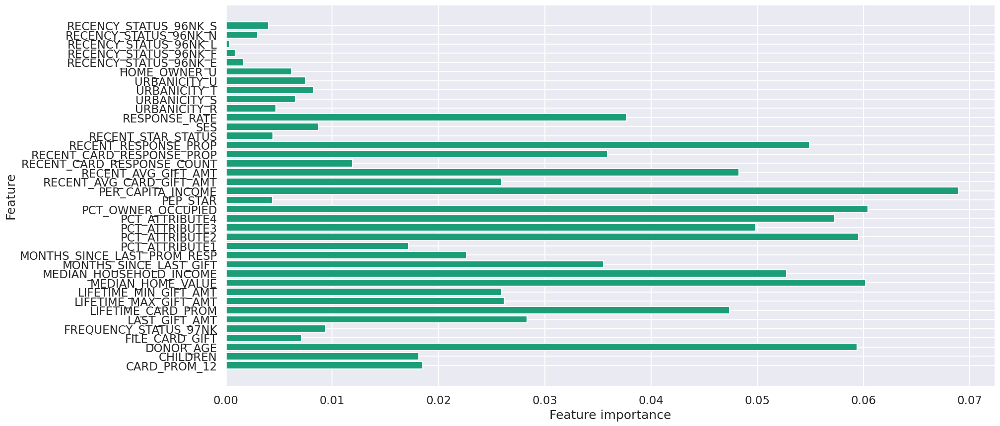

In [196]:
plot_feature_importances(modelDT)

#### 7.2.1 Parameter Tunning

#### a) Entropy

In [197]:
modelDT_entropy = DecisionTreeClassifier(criterion='entropy')

In [198]:
modelDT_entropy.fit(X_train, Y_train)

DecisionTreeClassifier(criterion='entropy')

In [199]:
labels_train_dt_entropy = modelDT_entropy.predict(X_train)
labels_val_dt_entropy = modelDT_entropy.predict(X_val)

In [200]:
print('Train:', f1_score(Y_train, labels_train_dt_entropy))
print('Validation:', f1_score(Y_val, labels_val_dt_entropy))

Train: 1.0
Validation: 0.28612099644128114


In [201]:
modelDT_entropy.score(X_train, Y_train)

1.0

In [202]:
modelDT_entropy.score(X_val, Y_val)

0.6301622418879056

In [203]:
dot_data = tree.export_graphviz(modelDT_entropy, out_file=None,
                     feature_names=X_train.columns,
                     class_names=["Donor", "Not Donor"],  # only to classification problems
                     filled=True)
pydot_graph = pydotplus.graph_from_dot_data(dot_data)
pydot_graph.set_size('"60, 60!"')
gvz_graph = graphviz.Source(pydot_graph.to_string())
gvz_graph

#### b) Depth

In [204]:
from sklearn.model_selection import GridSearchCV

param_grid = {'max_depth': [3, 4, 5, 7, 8, 10]}
grid_search = GridSearchCV(DecisionTreeClassifier(), param_grid, cv=5)
grid_search.fit(X_train, Y_train)

print(f"Best depth: {grid_search.best_params_['max_depth']}")

Best depth: 3


In [205]:
modelDT_maxdepth3 = DecisionTreeClassifier(criterion = 'entropy', max_depth=3,  class_weight='balanced',
    random_state=42)

In [206]:
modelDT_maxdepth3.fit(X_train, Y_train)

DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=3, random_state=42)

In [207]:
modelDT_maxdepth3.score(X_train, Y_train)

0.6436209439528023

In [208]:
modelDT_maxdepth3.score(X_val, Y_val)

0.6828908554572272

In [209]:
labels_train_dt_maxdepth3 = modelDT_maxdepth3.predict(X_train)
labels_val_dt_maxdepth3 = modelDT_maxdepth3.predict(X_val)

In [210]:
print('Train:', f1_score(Y_train, labels_train_dt_maxdepth3))
print('Validation:', f1_score(Y_val, labels_val_dt_maxdepth3))

Train: 0.38104386807556834
Validation: 0.2785234899328859


In [211]:
modelDT_maxdepth3.predict_proba(X_val)

array([[0.62273642, 0.37726358],
       [0.62273642, 0.37726358],
       [0.62273642, 0.37726358],
       ...,
       [0.62273642, 0.37726358],
       [0.504164  , 0.495836  ],
       [0.4555524 , 0.5444476 ]], shape=(2712, 2))

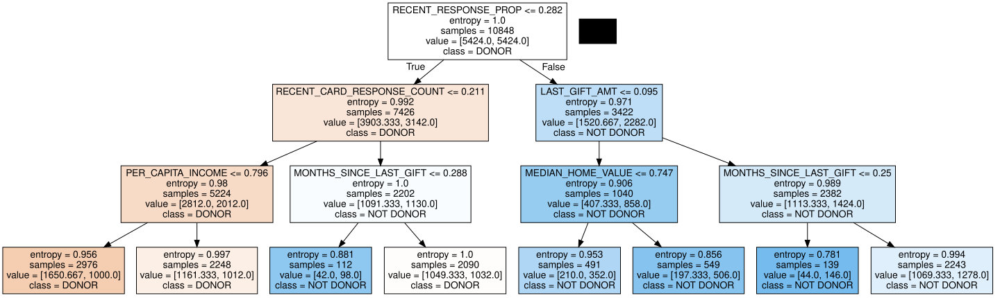

In [212]:
dot_data = tree.export_graphviz(modelDT_maxdepth3, out_file=None,
                     feature_names=X_train.columns,
                     class_names=["DONOR", "NOT DONOR"],  # only to classification problems
                     filled=True)
pydot_graph = pydotplus.graph_from_dot_data(dot_data)
pydot_graph.set_size('"20, 20!"')
gvz_graph = graphviz.Source(pydot_graph.to_string())
gvz_graph

#### c) Leaf

In [213]:
param_grid = {'max_leaf_nodes': [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]}

grid_search = GridSearchCV(DecisionTreeClassifier(criterion='entropy', max_depth=3), param_grid, cv=5)
grid_search.fit(X_train, Y_train)

print(f"Optimal Leaf Nodes: {grid_search.best_params_['max_leaf_nodes']}")

Optimal Leaf Nodes: 10


In [214]:
modelDT_leafs = DecisionTreeClassifier(max_leaf_nodes=10, criterion = 'entropy', max_depth=3,  class_weight='balanced',
    random_state=42)

In [215]:
modelDT_leafs.fit(X_train, Y_train)

DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=3, max_leaf_nodes=10, random_state=42)

In [216]:
modelDT_leafs.score(X_train, Y_train)

0.6436209439528023

In [217]:
modelDT_leafs.score(X_val, Y_val)

0.6828908554572272

In [218]:
labels_train_dt_leafs = modelDT_leafs.predict(X_train)
labels_val_dt_leafs = modelDT_leafs.predict(X_val)

In [219]:
print('Train:', f1_score(Y_train, labels_train_dt_leafs))
print('Validation:', f1_score(Y_val, labels_val_dt_leafs))

Train: 0.38104386807556834
Validation: 0.2785234899328859


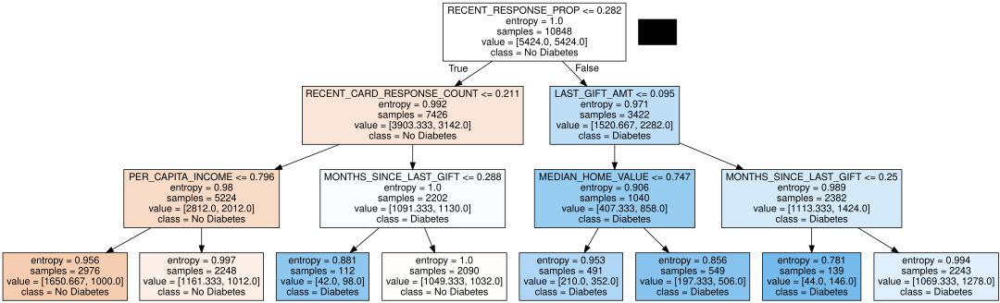

In [220]:
dot_data = tree.export_graphviz(modelDT_leafs, out_file=None,
                     feature_names=X_train.columns,
                     class_names=["No Diabetes", "Diabetes"],  # only to classification problems
                     filled=True)
pydot_graph = pydotplus.graph_from_dot_data(dot_data)
pydot_graph.set_size('"15, 15!"')
gvz_graph = graphviz.Source(pydot_graph.to_string())
gvz_graph

### 7.3 Neural Networks

Why Multilayer?
A single-layer network can only find a straight line to separate donors from non-donors.
A Multilayer network uses "hidden" neurons to create complex, non-linear boundaries

In [221]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
mlp = MLPClassifier()

In [222]:
def model_scores(mlp, X_train, Y_train, X_val, Y_val):
  mlp.fit(X_train, Y_train)

  # predict for the train
  pred_train = mlp.predict(X_train)

  # predict for val
  pred_val = mlp.predict(X_val)

  #create variables for scores
  acc_train = accuracy_score(Y_train, pred_train)
  acc_val = accuracy_score(Y_val, pred_val)
  precision_train = precision_score(Y_train, pred_train)
  precision_val = precision_score(Y_val, pred_val)
  recall_train = recall_score(Y_train, pred_train)
  recall_val = recall_score(Y_val, pred_val)
  f1_train = f1_score(Y_train, pred_train)
  f1_val = f1_score(Y_val, pred_val)

  #store results in df
  model_results = pd.DataFrame(data = {
                                              'Train_Acc' :acc_train,
                                              'Val_acc': acc_val,
                                              'Train_Precision': precision_train,
                                              'Val_Precision' : precision_val,
                                              'Train_Recall' : recall_train,
                                              'Val_Recall' : recall_val,
                                              'Train_F1': f1_train,
                                              'Val_F1' : f1_val,
                                              },
                                  index = ["mlp"])
  return model_results



In [223]:
model_scores(mlp, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.779406,0.732301,0.768067,0.318182,0.16851,0.061947,0.276383,0.103704


default mlp with two hidden layers, the first one with 19 hidden neurons (rule of thumb: (size of input layer + sixe of output layer)/2), and the second layer with half the size of the first one)

In [224]:
mlp1 = MLPClassifier(hidden_layer_sizes=(19,10))
model_scores(mlp1, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.759403,0.743732,0.674658,0.345455,0.07264,0.028024,0.131158,0.051842


default mlp with two hidden layers, the first one with 19 hidden neurons (rule of thumb: (size of input layer + sixe of output layer)/2), and the second layer with square root of the size of the first one)

In [225]:
mlp2 = MLPClassifier(hidden_layer_sizes=(19,4))
model_scores(mlp2, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.761338,0.693215,0.632829,0.294118,0.108038,0.162242,0.184567,0.209125


default mlp with two hidden layers, the first one with 25 hidden neurons (2/3 of the size of the input layer), and the second layer with half the size of the first one)

In [226]:
mlp3 = MLPClassifier(hidden_layer_sizes=(25,12))
model_scores(mlp3, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.767146,0.706121,0.630986,0.307443,0.165192,0.140118,0.261835,0.192503


default mlp with two hidden layers, the first one with 25 hidden neurons (2/3 of the size of the input layer), and the second layer with the square root of the size of the first one)

In [227]:
mlp4 = MLPClassifier(hidden_layer_sizes=(25,5))
model_scores(mlp4, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.757375,0.738569,0.665289,0.333333,0.059366,0.045723,0.109005,0.080415


default mlp with three hidden layers, the first one with 19 hidden neurons (rule of thumb: (size of input layer + sixe of output layer)/2), the second layer with half the size of the first one and the third one with half the size of the second one)

In [228]:
mlp5 = MLPClassifier(hidden_layer_sizes=(19,10,5))
model_scores(mlp5, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.761246,0.734145,0.622984,0.227848,0.113938,0.026549,0.192643,0.047556


In [229]:
mlp6 = MLPClassifier(hidden_layer_sizes=(38, 19))
model_scores(mlp6, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.774982,0.692847,0.640999,0.299742,0.227139,0.171091,0.335421,0.21784


In [230]:
mlp7 = MLPClassifier(hidden_layer_sizes=(40, 20))
model_scores(mlp7, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.780881,0.717183,0.69275,0.303965,0.221976,0.10177,0.336219,0.152486


In [231]:
mlp8 = MLPClassifier(hidden_layer_sizes=(40, 30))
model_scores(mlp8, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.787334,0.685103,0.694151,0.274359,0.266962,0.157817,0.385619,0.200375


In [232]:
mlp9 = MLPClassifier(hidden_layer_sizes=(16, 8))
model_scores(mlp9, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.755808,0.727876,0.59292,0.352941,0.074115,0.106195,0.13176,0.163265


In [233]:
mlp10 = MLPClassifier(hidden_layer_sizes=(64, 32))
model_scores(mlp10, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.818031,0.716077,0.761331,0.301724,0.396386,0.103245,0.521339,0.153846


In [234]:
mlp11 = MLPClassifier(hidden_layer_sizes=(26, 26))
model_scores(mlp11, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.770465,0.738938,0.65678,0.302632,0.17146,0.033923,0.27193,0.061008


In [235]:
mlp12 = MLPClassifier(hidden_layer_sizes=(30, 30))
model_scores(mlp12, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.772493,0.712021,0.630064,0.291498,0.21792,0.106195,0.323836,0.155676


In [236]:
mlp13 = MLPClassifier(hidden_layer_sizes=(35, 35))
model_scores(mlp13, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.783647,0.689159,0.739816,0.28,0.207596,0.154867,0.324215,0.19943


In [237]:
mlp14 = MLPClassifier(hidden_layer_sizes=(27, 27), random_state=42)
model_scores(mlp14, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.773599,0.689897,0.695122,0.325482,0.168142,0.224189,0.270784,0.265502


In [238]:
mlp15 = MLPClassifier(hidden_layer_sizes=(28, 28), random_state=42)
model_scores(mlp15, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.768068,0.71792,0.64121,0.317992,0.164086,0.112094,0.261304,0.165758


In [239]:
mlp16 = MLPClassifier(hidden_layer_sizes=(29, 29), random_state=42)
model_scores(mlp16, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.768529,0.711652,0.757033,0.304511,0.109145,0.119469,0.190783,0.17161


In [240]:
mlp17 = MLPClassifier(hidden_layer_sizes=(32, 32), random_state=42)
model_scores(mlp17, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.77535,0.690265,0.713841,0.285714,0.169248,0.159292,0.273621,0.204545


In [241]:
mlp18 = MLPClassifier(hidden_layer_sizes=(33, 33), random_state=42)
model_scores(mlp18, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.776733,0.737463,0.769517,0.385135,0.152655,0.084071,0.254769,0.138015


In [242]:
mlp19 = MLPClassifier(hidden_layer_sizes=(34, 34), random_state=42)
model_scores(mlp19, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.777655,0.702434,0.670843,0.252874,0.217183,0.097345,0.328134,0.140575


**The activation function of the hidden layers (default = 'relu')**

sigmoid function (sigmoid is the basis for logistic regression)

In [243]:
mlp_logistic = MLPClassifier(hidden_layer_sizes=(32,32), activation ='logistic', random_state=42)
model_scores(mlp_logistic, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.749723,0.75,0.2,0.0,0.000369,0.0,0.000736,0.0


In [244]:
mlp_logistic1 = MLPClassifier(hidden_layer_sizes=(30,30), activation ='logistic', random_state=42)
model_scores(mlp_logistic1, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.75,0.75,0.5,0.0,0.000369,0.0,0.000737,0.0


In [245]:
mlp_tanh = MLPClassifier(hidden_layer_sizes=(32,32), activation ='tanh', random_state=42)
model_scores(mlp_tanh, X_train, Y_train, X_val, Y_val)

,Train_Acc,Val_acc,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,Val_F1
mlp,0.757743,0.733407,0.701923,0.346939,0.053835,0.075221,0.1,0.123636


In [246]:
Y_train.value_counts()

,count
TARGET_B,
0.0,8136
1.0,2712


In [247]:
Y_val.value_counts()

,count
TARGET_B,
0.0,2034
1.0,678


# 8.Deployment

### 8.1 Importing the test data

In [248]:
test = pd.read_csv(path + 'test.csv' ,
                  sep = ',',
                  index_col = 'CONTROL_NUMBER'
                  )
test

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,...,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
122653,5.000000,0.0,72.0,M,1.0,1.0,H,4.0,25.0,13.000000,...,0.0,25.00,0.0,0.789208,1.0,0.071,0.0,2,T,NaN
184239,5.000000,3.0,73.0,U,20.0,4.0,U,NaN,6.0,32.000000,...,4.5,4.63,6.0,0.545000,8.0,0.421,1.0,2,C,1.0
5172,6.000000,2.0,36.0,M,11.0,NaN,H,4.0,10.0,44.352712,...,17.0,16.00,1.0,0.125000,2.0,0.111,1.0,3,R,1.0
135377,6.000000,3.0,NaN,F,2.0,4.0,U,2.0,10.0,9.000000,...,7.5,8.25,2.0,0.400000,4.0,0.364,0.0,1,U,NaN
62119,6.000000,0.0,83.0,F,9.0,2.0,U,2.0,20.0,31.000000,...,20.0,20.00,1.0,0.125000,2.0,NaN,1.0,2,T,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54438,6.000000,0.0,27.0,M,5.0,1.0,U,4.0,17.0,NaN,...,NaN,16.00,2.0,0.200000,2.0,0.095,13.0,2,R,8.0
122194,6.000000,1.0,42.0,M,3.0,2.0,H,7.0,20.0,11.000000,...,14.0,14.00,3.0,0.429000,3.0,0.214,0.0,1,C,NaN
106603,2.136786,0.0,81.0,F,8.0,3.0,H,2.0,10.0,21.000000,...,8.0,8.40,NaN,0.400000,5.0,0.238,0.0,3,T,NaN


### 8.2 Preprocessing

#### 8.2.1 Incoherence Treatment

In [249]:
test['DONOR_GENDER'] = test['DONOR_GENDER'].replace('U', np.nan)
test['SES'] = test['SES'].replace('?', np.nan)
test['URBANICITY'] = test['URBANICITY'].replace('?', np.nan)
test.loc[
    (test['RECENT_STAR_STATUS'] < 0) |
    (test['RECENT_STAR_STATUS'] > 1),
    'RECENT_STAR_STATUS'
] = 1

In [250]:
test['PEP_STAR'] = test['PEP_STAR'].clip(0, 1)

In [251]:
cols_pct = [
    'PCT_OWNER_OCCUPIED',
    'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2',
    'PCT_ATTRIBUTE3', 'PCT_ATTRIBUTE4'
]

for col in cols_pct:
    test[col] = test[col].clip(0, 100)

In [252]:
cols_prop = [
    'RECENT_CARD_RESPONSE_PROP',
    'RECENT_RESPONSE_PROP'
]

for col in cols_prop:
    test[col] = test[col].clip(0, 1)

In [253]:
test['DONOR_AGE'] = test['DONOR_AGE'].clip(18, 100)

In [254]:
cols_non_negative = [
    'MEDIAN_HOME_VALUE', 'RECENT_AVG_GIFT_AMT',
    'LIFETIME_GIFT_AMOUNT', 'LIFETIME_MAX_GIFT_AMT',
    'LIFETIME_MIN_GIFT_AMT', 'LAST_GIFT_AMT', 'PER_CAPITA_INCOME', 'MEDIAN_HOUSEHOLD_INCOME'
]

for col in cols_non_negative:
    test.loc[test[col] < 0, col] = np.nan

In [255]:
cols_int = [
    'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT',
    'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT',
    'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12',
    'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'RECENT_CARD_RESPONSE_COUNT'
]

for col in cols_int:
    test[col] = test[col].clip(lower=0).round().astype('Int64')

In [256]:
test.describe()

,CARD_PROM_12,CHILDREN,DONOR_AGE,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,INCOME_GROUP,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,...,PEP_STAR,PER_CAPITA_INCOME,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,WEALTH_RATING
count,5690.000000,5697.0,4356.000000,5697.0,5692.0,4456.000000,5665.000000,5700.000000,5668.000000,5685.0,...,5695.000000,5656.000000,5678.0,5673.000000,5708.0,5700.000000,5693.0,5681.000000,5702.000000,3143.000000
mean,5.338515,2.018782,59.190312,5.331578,1.975228,3.855307,16.613623,18.731444,105.223410,10.019525,...,0.506585,15828.529039,11.658154,15.440848,1.714436,0.228309,3.024767,0.189620,0.330235,4.954159
std,1.284803,1.463087,16.976983,4.702241,1.121467,1.972557,11.270483,8.917036,105.496841,8.692544,...,0.500001,8526.264654,10.661075,10.279939,1.553357,0.187843,2.062938,0.115639,0.470339,3.046115
min,0.000000,0.0,18.000000,0.0,0.0,-1.728999,0.000000,-7.188999,15.000000,0.0,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,-3.751835
25%,5.000000,1.0,47.000000,2.0,1.0,2.000000,10.000000,11.000000,42.000000,4.0,...,0.000000,10774.000000,5.0,10.000000,1.0,0.100000,2.0,0.105000,0.000000,2.000000
50%,6.000000,2.0,60.000000,4.0,2.0,4.000000,15.000000,19.000000,80.000000,8.0,...,1.000000,13701.500000,10.0,14.000000,1.0,0.200000,2.0,0.158000,0.000000,5.000000
75%,6.000000,3.0,73.000000,8.0,3.0,5.000000,20.000000,26.000000,131.000000,14.0,...,1.000000,18302.500000,16.0,20.000000,2.0,0.333000,4.0,0.250000,1.000000,8.000000
max,13.000000,6.0,100.000000,41.0,5.0,9.490799,205.000000,56.000000,1765.000000,89.0,...,1.000000,106273.000000,150.0,200.000000,9.0,1.000000,15.0,1.000000,1.000000,13.446890


#### 8.2.2 Missing Values

In [257]:
test['missing_percentage'] = test.isnull().sum(axis=1) / test.shape[1] * 100

#keep all rows with missing percentage below 50
test = test[test['missing_percentage'] < 50]

#delete this variable as we have no other need for it
del test['missing_percentage']

#check the number of nans in every columns now
test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5812 entries, 122653 to 65406
Data columns (total 39 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CARD_PROM_12                 5690 non-null   float64
 1   CHILDREN                     5697 non-null   Int64  
 2   DONOR_AGE                    4356 non-null   float64
 3   DONOR_GENDER                 5389 non-null   object 
 4   FILE_CARD_GIFT               5697 non-null   Int64  
 5   FREQUENCY_STATUS_97NK        5692 non-null   Int64  
 6   HOME_OWNER                   5693 non-null   object 
 7   INCOME_GROUP                 4456 non-null   float64
 8   LAST_GIFT_AMT                5665 non-null   float64
 9   LIFETIME_CARD_PROM           5700 non-null   float64
 10  LIFETIME_GIFT_AMOUNT         5668 non-null   float64
 11  LIFETIME_GIFT_COUNT          5685 non-null   Int64  
 12  LIFETIME_MAX_GIFT_AMT        5677 non-null   float64
 13  LIFETIME_MIN_GIFT

In [258]:
missing_counts = test.isna().sum()
missing_percentages = (test.isna().sum() / test.shape[0]) * 100
total_rows = test.shape[0]

missing_info = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentages,
    'Total Rows': total_rows
})

missing_info = missing_info.sort_values(by='Missing Count', ascending=False)

display(missing_info[missing_info['Missing Count'] > 0])

,Missing Count,Missing Percentage (%),Total Rows
WEALTH_RATING,2669,45.922230,5812
DONOR_AGE,1456,25.051617,5812
INCOME_GROUP,1356,23.331039,5812
DONOR_GENDER,423,7.278045,5812
URBANICITY,258,4.439092,5812
SES,248,4.267034,5812
MONTHS_SINCE_LAST_PROM_RESP,191,3.286304,5812
MEDIAN_HOME_VALUE,166,2.856160,5812
MEDIAN_HOUSEHOLD_INCOME,159,2.735719,5812
PER_CAPITA_INCOME,156,2.684102,5812


In [259]:
test.drop('INCOME_GROUP', axis = 1, inplace = True)

In [260]:
test.drop('WEALTH_RATING', axis = 1, inplace = True)

Datatypes

In [261]:
test[['DONOR_AGE', 'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT', 'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT', 'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12', 'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'SES']] = test[['DONOR_AGE', 'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT', 'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT', 'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12', 'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'SES']].astype('Int64')

KNN Imputer

In [262]:
test_original = test.copy()

# selecionar apenas variáveis numéricas
num_cols = test_original.select_dtypes(include=np.number).columns

test_num = test_original[num_cols].copy()

In [263]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
test_scaled = scaler.fit_transform(test_num)
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)

test_imputed_scaled = imputer.fit_transform(test_scaled)

In [264]:
test_imputed = scaler.inverse_transform(test_imputed_scaled)

test_imputed = pd.DataFrame(
    test_imputed,
    columns=num_cols,
    index=test_original.index
)

In [265]:
test_clean = test_original.copy()
test_clean[num_cols] = test_imputed

In [266]:
test_clean

,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,...,RECENCY_STATUS_96NK,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
122653,5.000000,0.0,72.0,M,1.0,1.0,H,25.0,13.000000,37.0,...,E,0.0,25.00,0.0,0.789208,1.0,0.0710,0.0,2.0,T
184239,5.000000,3.0,73.0,NaN,20.0,4.0,U,6.0,32.000000,126.0,...,S,4.0,4.63,6.0,0.545000,8.0,0.4210,1.0,2.0,C
5172,6.000000,2.0,36.0,M,11.0,2.4,H,10.0,44.352712,191.0,...,S,17.0,16.00,1.0,0.125000,2.0,0.1110,1.0,3.0,R
135377,6.000000,3.0,53.8,F,2.0,4.0,U,10.0,9.000000,33.0,...,N,8.0,8.25,2.0,0.400000,4.0,0.3640,0.0,1.0,U
62119,6.000000,0.0,83.0,F,9.0,2.0,U,20.0,31.000000,135.0,...,S,20.0,20.00,1.0,0.125000,2.0,0.1384,1.0,2.0,T
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54438,6.000000,0.0,27.0,M,5.0,1.0,U,17.0,20.000000,73.0,...,A,13.2,16.00,2.0,0.200000,2.0,0.0950,1.0,2.0,R
122194,6.000000,1.0,42.0,M,3.0,2.0,H,20.0,11.000000,42.0,...,A,14.0,14.00,3.0,0.429000,3.0,0.2140,0.0,1.0,C
106603,2.136786,0.0,81.0,F,8.0,3.0,H,10.0,21.000000,92.0,...,A,8.0,8.40,2.2,0.400000,5.0,0.2380,0.0,3.0,T


In [267]:
columns_to_int = [
    'DONOR_AGE', 'CHILDREN', 'FREQUENCY_STATUS_97NK', 'FILE_CARD_GIFT',
    'LIFETIME_PROM', 'RECENT_AVG_CARD_GIFT_AMT', 'RECENT_RESPONSE_COUNT',
    'MONTHS_SINCE_LAST_PROM_RESP', 'LIFETIME_GIFT_COUNT', 'NUMBER_PROM_12',
    'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_FIRST_GIFT', 'SES'
]

for col in columns_to_int:
    if col in test_clean.columns:
        # Round the values before converting to Int64 to avoid TypeErrors
        test_clean[col] = test_clean[col].round().astype('Int64')

print("Data types after converting to Int64:")
display(test_clean[columns_to_int].head())

Data types after converting to Int64:


,DONOR_AGE,CHILDREN,FREQUENCY_STATUS_97NK,FILE_CARD_GIFT,LIFETIME_PROM,RECENT_AVG_CARD_GIFT_AMT,RECENT_RESPONSE_COUNT,MONTHS_SINCE_LAST_PROM_RESP,LIFETIME_GIFT_COUNT,NUMBER_PROM_12,MONTHS_SINCE_LAST_GIFT,MONTHS_SINCE_FIRST_GIFT,SES
CONTROL_NUMBER,,,,,,,,,,,,,
122653,72,0,1,1,33,0,1,18,3,12,18,50,2
184239,73,3,4,20,70,4,8,21,29,9,21,128,2
5172,36,2,2,11,99,17,2,16,18,23,5,130,3
135377,54,3,4,2,26,8,4,16,4,17,16,23,1
62119,83,0,2,9,73,20,2,16,15,12,16,127,2


#### 8.2.3 Feature engineering

In [268]:
test_clean['TOTAL_AVG_GIFT'] = test_clean['LIFETIME_GIFT_AMOUNT'] / test_clean['LIFETIME_GIFT_COUNT']

In [269]:
test_clean['RESPONSE_RATE'] = test_clean['RECENT_RESPONSE_COUNT'] / test_clean['NUMBER_PROM_12']

In [270]:
# Handle infinite values in val_clean before scaling
for col in test_clean.columns:
    if test_clean[col].dtype == 'Float64' or test_clean[col].dtype == 'float64':
        # Replace positive infinities with the maximum finite value in the column
        max_finite = test_clean[col][np.isfinite(test_clean[col])].max()
        test_clean[col] = test_clean[col].replace(np.inf, max_finite if pd.notna(max_finite) else 0)

        # Replace negative infinities with the minimum finite value in the column
        min_finite = test_clean[col][np.isfinite(test_clean[col])].min()
        test_clean[col] = test_clean[col].replace(-np.inf, min_finite if pd.notna(min_finite) else 0)

In [271]:
test_clean['TOTAL_AVG_GIFT'] = test_clean['TOTAL_AVG_GIFT'].fillna(0)

In [272]:
test_clean['TOTAL_AVG_GIFT'] = test_clean['TOTAL_AVG_GIFT'].fillna(0)

#### 8.2.4 Encoding

In [273]:
cat_data3 = test_clean[['DONOR_GENDER', 'URBANICITY', "HOME_OWNER", 'RECENCY_STATUS_96NK']].copy()

In [274]:
dummy3 = pd.get_dummies(cat_data3, drop_first = True)
dummy3.head()

,DONOR_GENDER_M,URBANICITY_R,URBANICITY_S,URBANICITY_T,URBANICITY_U,HOME_OWNER_U,RECENCY_STATUS_96NK_E,RECENCY_STATUS_96NK_F,RECENCY_STATUS_96NK_L,RECENCY_STATUS_96NK_N,RECENCY_STATUS_96NK_S
CONTROL_NUMBER,,,,,,,,,,,
122653,True,False,False,True,False,False,True,False,False,False,False
184239,False,False,False,False,False,True,False,False,False,False,True
5172,True,True,False,False,False,False,False,False,False,False,True
135377,False,False,False,False,True,True,False,False,False,True,False
62119,False,False,False,True,False,True,False,False,False,False,True


In [275]:
test_clean = pd.concat([test_clean, dummy3], axis=1)

In [276]:
test_clean.drop('DONOR_GENDER', axis = 1, inplace = True)

In [277]:
test_clean.drop('HOME_OWNER', axis = 1, inplace = True)

In [278]:
test_clean.drop('URBANICITY', axis = 1, inplace = True)

In [279]:
test_clean.drop('RECENCY_STATUS_96NK', axis = 1, inplace = True)

In [280]:
test_clean[dummy3.columns] = test_clean[dummy3.columns].replace({True: 1, False: 0})

In [281]:
test_clean

,CARD_PROM_12,CHILDREN,DONOR_AGE,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,LAST_GIFT_AMT,LIFETIME_CARD_PROM,LIFETIME_GIFT_AMOUNT,LIFETIME_GIFT_COUNT,LIFETIME_MAX_GIFT_AMT,...,URBANICITY_R,URBANICITY_S,URBANICITY_T,URBANICITY_U,HOME_OWNER_U,RECENCY_STATUS_96NK_E,RECENCY_STATUS_96NK_F,RECENCY_STATUS_96NK_L,RECENCY_STATUS_96NK_N,RECENCY_STATUS_96NK_S
CONTROL_NUMBER,,,,,,,,,,,,,,,,,,,,,
122653,5.000000,0,72,1,1,25.0,13.000000,37.0,3,25.000000,...,0,0,1,0,0,1,0,0,0,0
184239,5.000000,3,73,20,4,6.0,32.000000,126.0,29,6.000000,...,0,0,0,0,1,0,0,0,0,1
5172,6.000000,2,36,11,2,10.0,44.352712,191.0,18,17.000000,...,1,0,0,0,0,0,0,0,0,1
135377,6.000000,3,54,2,4,10.0,9.000000,33.0,4,67.833657,...,0,0,0,1,1,0,0,0,1,0
62119,6.000000,0,83,9,2,20.0,31.000000,135.0,15,20.000000,...,0,0,1,0,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54438,6.000000,0,27,5,1,17.0,20.000000,73.0,7,17.000000,...,1,0,0,0,1,0,0,0,0,0
122194,6.000000,1,42,3,2,20.0,11.000000,42.0,3,20.000000,...,0,0,0,0,0,0,0,0,0,0
106603,2.136786,0,81,8,3,10.0,21.000000,92.0,14,10.000000,...,0,0,1,0,0,0,0,0,0,0


#### 8.2.5 Scaling the test data

In [282]:
scaler = MinMaxScaler().fit(test_clean)
minmax_val = scaler.transform(test_clean)

In [283]:
# Final Feature Selection for the test dataset
test_selected = pd.DataFrame(minmax_val, columns=test_clean.columns, index=test_clean.index)

# Keep only the features present in X_train
# This ensures both datasets have the exact same columns in the same order
missing_cols_in_test = [col for col in X_train.columns if col not in test_selected.columns]
for col in missing_cols_in_test:
    test_selected[col] = 0

X_test = test_selected[X_train.columns].copy()
print("X_test shape:", X_test.shape)
print("Are features matching exactly?", list(X_test.columns) == list(X_train.columns))

X_test shape: (5812, 38)
Are features matching exactly? True


In [284]:
# Deploying and predicting with the trained models on the test dataset
test_preds_log_reg = log_reg.predict(X_test)
test_preds_dt = modelDT_maxdepth3.predict(X_test)

# Display summary of predictions
unique_lr, counts_lr = np.unique(test_preds_log_reg, return_counts=True)
unique_dt, counts_dt = np.unique(test_preds_dt, return_counts=True)

print("Logistic Regression Prediction Counts:\n", dict(zip(unique_lr, counts_lr)))
print("Decision Tree Prediction Counts:\n", dict(zip(unique_dt, counts_dt)))

Logistic Regression Prediction Counts:
 {np.float64(0.0): np.int64(2981), np.float64(1.0): np.int64(2831)}
Decision Tree Prediction Counts:
 {np.float64(0.0): np.int64(4676), np.float64(1.0): np.int64(1136)}


#### 8.2.6 Feature Selection